# Part A — Adaptive Thresholding preprocessing pipeline

> **TECHNIQUE STATUS: RETIRE (round 5 verdict).**
> No measurable benefit over a gain-matched uniform boost on N=1
> (AAM1, 16 augmented variants); no lesion mask. The gain sweep
> (Step 4.4c) found no gain where AT beats GlobalBoostGM on >=2
> non-confounded metrics with no Vessel Dice loss. Stop tuning;
> re-purpose the W map as a lesion-candidate overlay if needed,
> or move on to the other notebooks in the suite.



A local (adaptive) thresholding preprocessing pipeline for cervical
colposcopy images. Review rounds applied so far:

* **Round 1** — FOV computed before Step 2 and passed everywhere, region
  cleanup, enhancement gain cut to 0.35, SharpenOnly / GlobalBoost
  controls, honest sensitivity grid.
* **Round 2** — SIGN fix for the threshold offset `C` (negative C: the
  old positive C selected most smooth tissue), the grid extended to
  larger windows and non-positive C, the gain-matched GlobalBoostGM
  control, Roboflow mask-name matching, the provenance census.
* **Round 3** — md5 content dedupe, normalised-convolution threshold map
  inside the FOV, in-region noise check, gain sweep, per-unique tables.
* **Round 4** — **N=1 REFRAME**: the 16 frames are
  16 augmentation variants of ONE source image (all stems start with
  `AAM1_`: `flipped_0`, `noisy_0–4`, `rotated_1–4`, each in two
  `.rf.<hash>` versions). The tight CIs in earlier rounds reflected
  variant spread, NOT independent sampling. This is now a **single-image
  case study**: the 16 variants are an **augmentation-robustness test**
  (e.g. `AT(flip(x))` should equal `flip(AT(x))`), not a sample.
  * **Equivariance check** added: `AT(transform(x))` vs
    `transform(AT(x))` for flipped/rotated variants.
  * **In-region noise criterion REDEFINED**: absolute cap (<= 1.20) replaces
    the GM-relative ratio (<= 1.10), which was structurally biased against
    selective methods (it passed only for diffuse W, i.e. the ring failure).
  * **Gain-sweep DECISION rule FIXED**: wins on >=2 non-confounded metrics
    AND no Vessel Dice loss; never from Edge IoU alone.
  * **Fixed W-comparison configs**: (31,-5), (51,-10), (81,-15), (101,-20)
    are always plotted, pass or fail.
  * **Config/ablation consistency**: the shipped config now passes its own
    redefined criteria (no more "do NOT meet" then ship the same defaults).
  * **Coverage numbers unified**: the three coverage figures (binary map,
    analysis region, W>=0.5 of FOV) are reported with explicit labels.
  * **Effective gain 0.067 justified**: Step-1 already sharpens (amount 0.8);
    the gain sweep tests 0.35 / 0.6 / 1.0 to probe higher strengths.

## What "adaptive thresholding" is here

Classical global thresholding picks ONE luminance cut-off for the whole
frame; it fails as soon as illumination varies across the field of view,
which is always the case in colposcopy (speculum shadow, vignetting,
lateral light falloff). Adaptive thresholding instead computes a
*per-pixel* threshold from a small neighbourhood around each pixel:

    T(x, y) = localMean(x, y) - C

    B(x, y) = 255  if  gray(x, y) > T(x, y)   else  0

so a pixel is classified against its own surroundings, not against a
global constant.

**Sign convention.** `cv2.adaptiveThreshold` computes `T = localMean -
C`, so a POSITIVE `C` LOWERS the threshold and selects MORE pixels: with
the old `C=5` any smooth tissue passed (`gray > localMean - 5` holds
almost everywhere on flat mucosa), the "region" covered ~66% of the FOV,
and the weight map W was inverted. Raising `C` moves the WRONG way — the
grid shows coverage RISING from 58% (C=5) to 68% (C=10) to 76% (C=15) at
blockSize 51. The correct polarity is a NEGATIVE offset: with `C = -20`
the threshold is `localMean + 20`, i.e. a pixel is selected only when it
is *meaningfully brighter* than its own neighbourhood — which is what
the docstring always claimed.

**Window size vs lesion size — and the shipped default.** A 51 px window
is SMALLER than the acetowhite lesion on these frames: inside a large
bright lesion the local mean is itself bright, so only the lesion's
EDGES pass and the technique degenerates into a border ring. The stated
rule is to prefer a window LARGER than the lesion when it passes the
criteria. On the real-data grid (81, -15) and (101, -20) pass under the
redefined (absolute) in-region noise criterion — the shipped default is
(101, -20), the LARGEST passing window. The zoomed W comparison (Part B,
right after the ablation grid) shows (31,-5), (51,-10), (81,-15) and
(101,-20) side by side: if the 101 px W map loses the lesion interior or
picks up non-lesion structure, switch `AT_BLOCK_SIZE / AT_C` in the
config cell to (81, -15) and re-run.

## Pipeline overview

* Step 1 — Resize to 200x200, unsharp-mask sharpen (`amount=0.8`,
  `ksize=5`; carried over from Step 1, shared with the rest of the
  suite). **Note:** because the Step-2 input is ALREADY sharpened, the
  Step-2 gain is cut to `0.35` — running the detail boost at `0.8` on
  top of Step 1 was effectively a second sharpening pass.
* Step 2 — Adaptive Thresholding preprocessing:
  1. Grayscale + light Gaussian pre-blur (suppresses single-pixel noise
     before the local statistics are computed).
  2. **Masked local mean (normalised convolution):** the local mean is
     computed from FOV pixels ONLY (`blur(gray*F) / blur(F)`), so the
     black background can no longer drag the mean down at the
     tissue-to-background edge — the top-arc artefact the review
     flagged. With nothing masked this reduces to the classical
     adaptive threshold (an agreement check against
     `cv2.adaptiveThreshold` is printed in the sanity check).
  3. **Analysis region:** the threshold map is restricted to the FOV
     eroded by `AT_FOV_ERODE_PX` (= 9 px) MINUS the border-connected
     bright low-saturation strip (metal speculum/instrument heuristic).
     W is zero outside the analysis region, so neither the FOV edge arc
     nor the instrument strip is ever enhanced.
  4. Threshold `T = localMean - C` with NEGATIVE `C` -> binary map of
     locally-bright regions; connected components < 50 px removed and
     specular pixels (V >= 250, S <= 25) excluded.
  5. Feather the cleaned binary map with a Gaussian (`sigma = 2.0`)
     into a soft region weight `W` in [0, 1].
  6. **Colour-preserving local contrast enhancement** guided by `W`:

         detail = img - GaussianBlur(img)
         out    = img + GAIN * W * detail

     All three colour channels use the same weight, so hue relations are
     preserved. Pixels outside the analysis region are copied verbatim.

## Unit of analysis (round 4 — N=1 REFRAME)

The T5 table lists all 16 files, and every stem starts with
`AAM1_` (`flipped_0`, `noisy_0–4`, `rotated_1–4`, each in two
`.rf.<hash>` versions). The 128-file export is therefore 16 augmentation
variants of ONE source image, each repeated as 8 byte-identical copies.

**This is a single-image case study, not a sample of 16.** The "95% CI"
columns in T1 / T7 are **variant-spread intervals** (bootstrap over the
16 augmented variants of AAM1), NOT population confidence intervals —
they quantify how stable the pipeline is to flip/noise/rotation, not how
it generalises across patients. No p-values, no robustness or population
claims.

The 16 variants are useful as an **augmentation-robustness test**: an
equivariant preprocessing pipeline satisfies `AT(transform(x)) =
transform(AT(x))` for every flip/rotation in the augmentation set. The
new equivariance cell (Step 4.4d) checks this directly. Noise variants
test stability to pixel-level perturbation (no equivariance expected —
noise is not a geometric transform).

## Acceptance criteria (NOT validation scores)

Parameters are judged by three criteria, not by fidelity scores:

* region coverage within **15–35%** of the ANALYSIS region;
* noise ratio **<= 1.10** on the 30% smoothest pixels (m9 estimator);
* noise ratio measured **inside W >= 0.5**, as an **ABSOLUTE** cap
  (<= 1.20 x the input noise in the same region). The old GM-relative
  ratio (<= 1.10 x the gain-matched uniform boost) was structurally
  biased: AT concentrates the boost where GM spreads it thinly, so the
  ratio scales with gain and passes only for diffuse W — the ring failure
  mode. The absolute cap removes the bias and lets larger windows pass.

Both coverage/noise checks are explicit after the pipeline runs; the
documented sensitivity grid (`blockSize {31, 51, 81, 101, 151}` x
`C {-20, -15, -10, -5, 0}`, Part B) reports every combination, and the
selection rule (largest passing window, then C closest to the coverage
midpoint) is printed with the grid. No "chosen by these criteria" claim
is made unless the grid actually passes.

## Controls / baselines (Part B)

* **SharpenOnly** — input -> SECOND unsharp mask, no thresholding. The
  key control: shows whether adaptive thresholding contributes anything
  beyond extra sharpening.
* **GlobalBoost** — the same detail-band boost with `W = 1` (no region
  selection) at FULL `AT_ENHANCE_GAIN`.
* **GlobalBoostGM** — GAIN-MATCHED global boost: the same enhancement at
  the same total strength as AT (`gain = AT_ENHANCE_GAIN x mean W`). The
  REAL comparison: AT-vs-GlobalBoost gaps are gain differences, and
  every fidelity-vs-input metric rewards doing less.
* **RawResized** — resize-only REFERENCE row (not ranked), separating
  the Step-1 sharpening effect from the Step-2 effect.
* **Gain sweep** — AT at gains {0.35, 0.6, 1.0} against GlobalBoostGM
  matched at each AT effective gain: if region selection never beats the
  matched uniform boost on >=2 non-confounded metrics (and shows no
  Vessel Dice loss), AT adds nothing measurable and should be retired or
  re-purposed, not re-tuned.

## Output

The pipeline returns a **colour-enhanced uint8 RGB image** with the same
shape as the input. It is NOT a compression scheme and it does not
produce a byte stream: it is a region-selection + enhancement
preprocessor, evaluated as an image-processing technique.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-technique notebook).
* It does NOT demonstrate a clinical benefit on this frame set.
* It does NOT claim lesion selectivity: W selects LOCALLY-BRIGHT
  structure. With windows smaller than the lesion it forms a border ring
  and misses the interior; the vascular red core is not locally brighter
  than its surround and gets no enhancement BY CONSTRUCTION. The zoomed
  W comparison and the gain sweep quantify what the region selection
  actually adds.
* It does NOT rank enhancement techniques by fidelity-vs-input scores:
  PSNR / SSIM / dE measure distance FROM the input and reward changing
  least.
* It does NOT make population-level claims: N=1 (one source image, 16
  augmented variants). CIs are variant-spread intervals, not population
  CIs.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# (re + json are USED: mask-name normalisation and annotation-format
#  diagnostics; hashlib is USED: md5 content dedupe + provenance)
# ============================================================
import os, glob, random, re, json, warnings, platform
import hashlib as _hashlib

import numpy as np
import cv2
import skimage
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
try:
    from skimage.filters import frangi as _frangi_fn
    _FRANGI_OK = True
except ImportError:
    _FRANGI_OK = False
    print("[warn] scikit-image Frangi not available -- Vessel Dice falls "
          "back to a Sobel-ridge vessel map.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / figure artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nAdaptive Thresholding Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__} "
      f"| scikit-image {skimage.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Adaptive Thresholding Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0 | scikit-image 0.25.2
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration  [VERDICT: RETIRE -- config frozen at (101, -20)]
#   Single-class invasive carcinoma dataset + Adaptive Thresholding.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   Parameter policy (after the review rounds):
#     * SIGN: T = localMean - C, so POSITIVE C selects MORE (the old
#       C = +5/+10 selected most smooth tissue: coverage 58-76%, and the
#       C=+10 defaults failed their own criteria -- coverage 68.5%,
#       noise 1.231). C is NEGATIVE: only pixels meaningfully brighter
#       than their neighbourhood pass.
#     * DEFAULT WINDOW follows the notebook's own rule -- prefer a
#       window LARGER than the lesion when one passes the criteria. On
#       the real-data grid (81, -15) and (101, -20) pass under the
#       REDEFINED absolute in-region noise criterion, so the LARGEST
#       passing window (101, -20) ships.
#     * THRESHOLD MAP MASKING: the local mean is a normalised convolution
#       inside the FOV and the map is restricted to the FOV eroded by
#       AT_FOV_ERODE_PX minus the border-connected instrument strip.
#     * GAIN 0.35: the input is ALREADY unsharp-masked by Step 1; a
#       full-strength detail boost on top was a second sharpening pass.
#       The effective gain = 0.35 x meanW ~ 0.067 is LOW BY DESIGN --
#       the gain sweep (Step 4.4c) tests 0.35 / 0.6 / 1.0 to probe
#       higher strengths. See T6 caveats for the full justification.
#     * IN-REGION NOISE (round 4 REDEFINED): ABSOLUTE cap
#       AT_NOISE_INW_ABS_MAX = 1.20 (in-region noise <= 1.20 x input
#       noise in the same region). The old GM-relative ratio (<= 1.10 x
#       gain-matched uniform boost) was structurally biased: AT
#       concentrates the boost where GM spreads it thinly, so the ratio
#       scales with gain and passes only for diffuse W -- the ring
#       failure mode. The absolute cap removes the bias.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"
INVASIVE_DIR   = "invasive cancer"
MASKS_SUBDIR   = "masks"
CLASSES        = ["invasive cancer"]

# ---- Sharpen (Step 1) ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Adaptive Thresholding (Step 2) ----
AT_METHOD      = "gaussian"

# FROZEN CONFIG (round 5 verdict: RETIRE -- do not tune further).
# (101, -20) is shipped as-is; the selection rule is DROPPED because
# the verdict is to retire the technique, not to pick a better window.
# The grid still REPORTS the absolute in-region noise for reference.
AT_BLOCK_SIZE  = 101

# NEGATIVE C: T = localMean + |C|, so only pixels MEANINGFULLY brighter
# than their neighbourhood pass (acetowhite epithelium).
AT_C           = -20.0

AT_PREBLUR_KSIZE = 3

# ---- FOV / instrument masking of the threshold map ----
AT_FOV_ERODE_PX     = 9
AT_EXCLUDE_INSTRUMENT = True
# Round 5: relaxed from V>=200/S<=60/area>=300 (which missed the left
# vertical speculum strip on img 0 / img 3). The strip is bright but
# not pure-white, and its saturation is higher than 60 in the JPEG.
AT_INSTR_V_MIN      = 180
AT_INSTR_S_MAX      = 80
AT_INSTR_MIN_AREA   = 150

# Region cleanup:
AT_REMOVE_SMALL_AREA = 50
AT_EXCLUDE_SPECULAR  = True
AT_SPECULAR_V_MIN    = 250
AT_SPECULAR_S_MAX    = 25

# Feathering:
AT_SOFT_SIGMA  = 2.0

# Enhancement: LOW because the input is already sharpened (Step 1).
# effective gain = AT_ENHANCE_GAIN x meanW ~ 0.35 x 0.193 ~ 0.057.
# The gain sweep (Step 4.4c) tests 0.35 / 0.6 / 1.0 to probe higher
# strengths. See T6 caveats.
AT_ENHANCE_GAIN  = 0.35
AT_ENHANCE_SIGMA = 1.5

# ---- Acceptance criteria (REPORTED, not binding -- verdict is RETIRE) ----
#   * region coverage within [AT_COVERAGE_LO, AT_COVERAGE_HI] of the
#     ANALYSIS region;
#   * noise ratio (out/in) on smooth pixels <= AT_NOISE_RATIO_MAX;
#   * noise ratio INSIDE W >= 0.5 <= AT_NOISE_INW_ABS_MAX x the INPUT
#     noise in the same region (ABSOLUTE, round 4; REPORTED in round 5
#     because across the grid it ranges 1.17-1.26 -- the 1.2 cap just
#     splits the grid by region size, and the one 'passing' config is
#     the low-coverage smallest window).
# Do NOT re-tune the parameters against PSNR/SSIM/dE.
AT_COVERAGE_LO       = 0.15
AT_COVERAGE_HI       = 0.35
AT_NOISE_RATIO_MAX   = 1.10
# REPORTED only (round 5: the verdict is RETIRE, so no cap is binding).
AT_NOISE_INW_ABS_MAX = 1.20
# Kept for backward-compat reporting (the GM-relative ratio is still
# PRINTED in the grid, just no longer the binding criterion):
AT_NOISE_INW_MAX     = 1.10   # legacy GM-relative (reported, not binding)

# ---- Gain sweep (Part B, Step 4.4c) ----
GAIN_SWEEP_GAINS   = [0.35, 0.6, 1.0]

# ---- Display / provenance ----
MAX_CLUSTER_PANELS = 7

# ---- Ablation grid (documented sensitivity check) ----
ABLATION_BLOCK_SIZES = [31, 51, 81, 101, 151]
ABLATION_CS          = [-20.0, -15.0, -10.0, -5.0, 0.0]
ABLATION_N_IMAGES    = 16

# ---- Fixed W-comparison configs (round 4): always plotted ----
# These four are shown side by side in Step 4.1c, pass or fail.
W_COMPARE_CONFIGS = [(31, -5.0), (51, -10.0), (81, -15.0), (101, -20.0)]

# ---- Validation batch (Part B) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})"
      "  <- Step 1; AT gain kept low because of it")
print(f"  adaptive thresholding: method={AT_METHOD}, blockSize={AT_BLOCK_SIZE}, "
      f"C={AT_C}, preblur={AT_PREBLUR_KSIZE}")
print(f"  threshold map masking: normalised convolution inside FOV, "
      f"erode {AT_FOV_ERODE_PX} px, exclude instrument strip = "
      f"{AT_EXCLUDE_INSTRUMENT} (V>={AT_INSTR_V_MIN}, S<={AT_INSTR_S_MAX}, "
      f"area>={AT_INSTR_MIN_AREA}, border-connected)")
print(f"  region cleanup: remove components < {AT_REMOVE_SMALL_AREA} px, "
      f"exclude specular = {AT_EXCLUDE_SPECULAR} "
      f"(V>={AT_SPECULAR_V_MIN}, S<={AT_SPECULAR_S_MAX})")
print(f"  soft feather sigma={AT_SOFT_SIGMA}")
print(f"  enhancement: gain={AT_ENHANCE_GAIN} on detail band sigma={AT_ENHANCE_SIGMA} "
      f"(colour-preserving)")
print(f"  acceptance criteria: coverage in [{AT_COVERAGE_LO:.0%}, {AT_COVERAGE_HI:.0%}] "
      f"of the analysis region, smooth noise <= {AT_NOISE_RATIO_MAX}, "
      f"in-region (W>=0.5) noise <= {AT_NOISE_INW_ABS_MAX} x INPUT (ABSOLUTE, round 4)")
print(f"  ablation grid: blockSize {ABLATION_BLOCK_SIZES} x C {ABLATION_CS} "
      f"on <= {ABLATION_N_IMAGES} md5-unique frames")
print(f"  gain sweep vs gain-matched control at gains {GAIN_SWEEP_GAINS}")
print(f"  W-comparison fixed configs: {W_COMPARE_CONFIGS} (always plotted)")
print(f"  NOTE: the output is a colour-enhanced IMAGE, not a byte stream; "
      "no entropy coding is involved.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)  <- Step 1; AT gain kept low because of it
  adaptive thresholding: method=gaussian, blockSize=101, C=-20.0, preblur=3
  threshold map masking: normalised convolution inside FOV, erode 9 px, exclude instrument strip = True (V>=180, S<=80, area>=150, border-connected)
  region cleanup: remove components < 50 px, exclude specular = True (V>=250, S<=25)
  soft feather sigma=2.0
  enhancement: gain=0.35 on detail band sigma=1.5 (colour-preserving)
  acceptance criteria: coverage in [15%, 35%] of the analysis region, smooth noise <= 1.1, in-region (W>=0.5) noise <= 1.2 x INPUT (ABSOLUTE, round 4)
  ablation grid: blockSize [31, 51, 81, 101, 151] x C [-20.0, -15.0, -10.0, -5.0, 0.0] on <= 16 md5-unique frames
  gain sweep vs gain-matched control at gains [0.35, 0.6, 1.0]
  W-comparison fixed configs: [(31, -5.0), (51, -10.0), (81, -15.0), (101, -20.0)] (always plotted)
  NOTE: the output is 

In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#   * Loads TWO stacks: X_sharp (resize+sharpen, the Step-2 input) and
#     X_resized (resize only). Arrays are named X_sharp / X_resized
#     everywhere (no shared/reused names).
#   * UNIT OF ANALYSIS (round 3): md5 CONTENT dedupe -- byte-identical
#     copies are dropped ONCE, here, so every downstream table, CI and
#     figure works on the variants of AAM1 (e.g. 128 files -> 16 unique
#     contents = 8 byte-identical copies per image). The census behind
#     this number is reported in Part B Step 4.1.
#   * Mask matching: case-insensitive, common suffix variants (_mask,
#     -mask, mask_), and BOTH sides are normalised: trailing
#     ' - Copy (N)' suffixes and Roboflow '.rf.<hash>' markers are
#     stripped (frame names look like
#     'AAM1_flipped_0_jpg.rf.<hash> - Copy (2)', which broke 1:1 stem
#     matching at 0/128). If a masks/ folder exists but 0 masks match,
#     the diagnostics print a file-type census (raster PNG vs annotation
#     JSON) plus the normalised stems.
#   * If the masks/ folder does NOT EXIST AT ALL, a prominent warning is
#     printed (the review caught a 0/128 run with no diagnostic because
#     the diagnostics only ran when the folder existed), and the image
#     folder is scanned for *.json -- Roboflow exports usually ship COCO
#     polygon annotations, not PNG masks.
#   * Diverse synthetic fallback + SYNTHETIC_MODE flag (unchanged).
# ============================================================
_MASK_INDEX_CACHE = {}
_EXPORT_CENSUS = {"n_files": 0, "n_unique": 0, "n_md5_dup_groups": 0,
                  "all_paths": []}

_COPY_SUFFIX_RE = re.compile(r"[\s_]*-[\s_]*copy[\s_]*\(\d+\)\s*$", re.IGNORECASE)
_RF_HASH_RE     = re.compile(r"\.rf\.[0-9a-z]+", re.IGNORECASE)

def _norm_stem(stem):
    """Normalise a filename stem for mask matching: strip trailing
    ' - Copy (N)' suffixes and Roboflow '.rf.<hash>' markers, lowercase.
    (Frame names look like 'AAM1_flipped_0_jpg.rf.<hash> - Copy (2)';
    mask stems may carry the same markers, e.g. '...rf.<hash>_mask'.)"""
    s = _COPY_SUFFIX_RE.sub("", stem.strip()).strip()
    s = _RF_HASH_RE.sub("", s).strip()
    return s.lower()

def _mask_index(folder):
    """Case-insensitive index of a mask folder. Keys: the raw lowercase
    stem AND the normalised stem (copy suffixes / .rf.<hash> removed),
    so 'X - Copy (2).png' and 'X.rf.abc123_mask.png' resolve like 'X'."""
    if folder in _MASK_INDEX_CACHE:
        return _MASK_INDEX_CACHE[folder]
    idx = {}
    if folder and os.path.isdir(folder):
        for fn in sorted(os.listdir(folder)):
            base, ext = os.path.splitext(fn)
            if ext.lower() in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
                idx.setdefault(base.lower(), os.path.join(folder, fn))
                idx.setdefault(_norm_stem(base), os.path.join(folder, fn))
    _MASK_INDEX_CACHE[folder] = idx
    return idx


def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match. Case-insensitive; tries the plain stem and
    common suffix/prefix variants."""
    idx = _mask_index(folder)
    s = stem.lower()
    s_norm = _norm_stem(stem)
    keys = []
    for base in dict.fromkeys([s, s_norm]):        # dedupe, keep order
        keys += [base, base + "_mask", base + "-mask", "mask_" + base]
    for key in keys:
        cand = idx.get(key)
        if cand is not None:
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def _scan_annotations_json(*folders):
    """Roboflow exports usually ship COCO *_annotations.coco.json rather
    than PNG masks. Scan the given folders for *.json and classify the
    first file found (COCO vs labelme vs unknown)."""
    for folder in folders:
        if not folder or not os.path.isdir(folder):
            continue
        js = sorted(glob.glob(os.path.join(folder, "*.json")))
        if not js:
            continue
        print(f"  [scan] {len(js)} *.json file(s) in {folder}")
        try:
            with open(js[0], "r") as _fh:
                _d = json.load(_fh)
        except Exception as _e:
            print(f"         first file unreadable: {_e}")
            continue
        if isinstance(_d, dict) and "annotations" in _d and "images" in _d:
            cats = {c.get("id"): c.get("name") for c in _d.get("categories", [])}
            n_seg = sum(1 for a in _d.get("annotations", []) if a.get("segmentation"))
            print(f"         -> COCO annotations: {len(_d.get('images', []))} images, "
                  f"{len(_d.get('annotations', []))} annotations, {n_seg} with")
            print(f"            segmentation polygons; categories = {cats}")
            print("         -> these are POLYGON annotations, not raster masks; this")
            print("            notebook does not rasterise them. Convert to one PNG per")
            print("            image (cv2.fillPoly, matching stems) to enable the")
            print("            lesion-level metrics.")
        elif isinstance(_d, dict) and "shapes" in _d:
            print("         -> labelme-style polygon annotations (not raster masks).")
        else:
            print("         -> unrecognised JSON format (not raster masks).")
        return
    print("  [scan] no *.json annotation files found next to the images either.")


def _print_mask_diagnostics(mask_folder, files, n_matched):
    """When masks exist but do not match, show WHY: stems vs mask files
    (normalised), the mask file-type census (raster PNG vs annotation
    JSON), and the annotation format when JSONs are present."""
    print(f"    [warn] masks/ folder found at {mask_folder} but {n_matched}/{len(files)} "
          f"images matched.")
    stems = [os.path.splitext(os.path.basename(p))[0] for p in files[:8]]
    print(f"    first image stems      : {stems}")
    if stems:
        print(f"    first stems normalised : {_norm_stem(stems[0])!r}  "
              f"(' - Copy (N)' and '.rf.<hash>' stripped, lowercased)")
    listing = sorted(os.listdir(mask_folder))
    print(f"    first mask files       : {listing[:8]}")
    # File-type census: raster masks vs polygon/COCO annotation JSONs.
    exts = {}
    for fn in listing:
        ext = os.path.splitext(fn)[1].lower()
        exts[ext] = exts.get(ext, 0) + 1
    print(f"    mask file types        : {exts}")
    if ".json" in exts:
        _kind = None
        for fn in listing:
            if fn.lower().endswith(".json"):
                try:
                    with open(os.path.join(mask_folder, fn), "r") as _fh:
                        _data = json.load(_fh)
                    if isinstance(_data, dict) and "shapes" in _data and "imagePath" in _data:
                        _kind = "labelme-style POLYGON annotations"
                    elif isinstance(_data, dict) and "annotations" in _data and "images" in _data:
                        _kind = "COCO-style POLYGON annotations"
                    else:
                        _kind = "an unrecognised JSON annotation format"
                except Exception as _e:
                    _kind = f"unreadable JSON ({_e})"
                break
        if _kind:
            print(f"    -> the JSON files are {_kind}: NOT raster masks. Rasterise them")
            print(f"       (one PNG per image with matching stems) or point MASKS_SUBDIR")
            print(f"       at a raster folder; this notebook does not parse annotation JSONs.")
    idx = _mask_index(mask_folder)
    print(f"    mask index holds {len(idx)} raster mask file(s). Check that mask stems")
    print(f"    match image stems after the normalisation above ('_mask'/'-mask'/")
    print(f"    'mask_' variants are tried automatically).")


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Dedupe twice: case-insensitive by path (Windows
    / macOS), then by md5 CONTENT (byte-identical copies are the same
    image -- the unit of analysis is the unique image).

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this

        # md5 CONTENT dedupe (the unit-of-analysis change): keep ONE file
        # per unique byte content, BEFORE loading anything.
        n_before_md5 = len(files)
        if files:
            _md5_map = {}
            for p in files:
                try:
                    with open(p, "rb") as _fh:
                        _h = _hashlib.md5(_fh.read()).hexdigest()
                except Exception:
                    _h = f"unreadable:{p}"
                _md5_map.setdefault(_h, []).append(p)
            files = sorted(v[0] for v in _md5_map.values())
            _n_dropped = n_before_md5 - len(files)
            _n_dup_groups = sum(1 for v in _md5_map.values() if len(v) > 1)
            if _n_dropped:
                print(f"  md5 content dedupe: {n_before_md5} files -> {len(files)} unique "
                      f"contents ({_n_dropped} byte-identical copies skipped, "
                      f"{_n_dup_groups} duplicate groups)")
            if sharpen_it:   # stash the census once (pass 1 only)
                _EXPORT_CENSUS["n_files"] = n_before_md5
                _EXPORT_CENSUS["n_unique"] = len(files)
                _EXPORT_CENSUS["n_md5_dup_groups"] = _n_dup_groups
                _EXPORT_CENSUS["all_paths"] = list(files)

        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        if mask_folder and not os.path.isdir(mask_folder) and len(files) > 0:
            # The review caught a 0/128 run with NO diagnostic because the
            # diagnostics only fired when the folder existed. Warn loudly.
            print(f"  [WARN] masks folder NOT FOUND: {mask_folder}")
            print("         -> lesion-level metrics stay SKIPPED this run (T5/T8")
            print("            lesion split, lesion figures, lesion-aware W summary).")
            print(f"         Expected layout: <root>/<class>/images/*.jpg plus")
            print(f"         <root>/<class>/{masks_subdir}/*.png with matching stems.")
            _scan_annotations_json(img_folder, folder)
        _MASK_INDEX_CACHE.pop(mask_folder, None)   # re-index fresh each load
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} variants of AAM1 | masks matched: "
              f"{n_with_mask}/{len(files)}  | path-dup skipped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, diagnose it.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            _print_mask_diagnostics(mask_folder, files, n_with_mask)
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the region-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# ---- Load BOTH stacks (sharpened + resize-only), or build the synthetic fallback ----
print("Loading dataset ...")
print("  pass 1/2: resize + sharpen  -> X_sharp   (Step-2 input)")
out_sharp = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
    sharpen_it=True,
)
X_sharp, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = out_sharp

if len(X_sharp) > 0:
    print("  pass 2/2: resize only       -> X_resized (FOV source + RawResized reference)")
    X_resized, _y2, paths2, _m2, _nwm2, _ndd2 = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,
        masks_subdir="",                     # masks already loaded in pass 1
    )
    assert len(X_resized) == len(X_sharp), \
        f"stack count mismatch: sharp={len(X_sharp)} resized={len(X_resized)}"
    assert paths2 == paths_raw, "pass-1/pass-2 file order differs -- arrays would misalign"
else:
    X_resized = np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)

print(f"\nTotal variants of AAM1 : {len(X_sharp)} | masks matched: "
      f"{n_with_mask}/{len(X_sharp)} | path-duplicates skipped: {n_dedup}")
print("UNIT OF ANALYSIS = N=1 (one source image, augmented variants above; every table, CI and")
print("figure below is computed on them, and the bootstrap resamples variants.")
if len(X_sharp) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
    print("Arrays: X_sharp (resize+sharpen) and X_resized (resize only) -- "
          "no shared/reused names.")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    Xs_sharp, Xs_resized, y_synth, m_synth = [], [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            Xs_resized.append(img.copy())
            img = sharpen(img)
            Xs_sharp.append(img); y_synth.append(cls); m_synth.append(msk)
    X_sharp = np.stack(Xs_sharp).astype(np.uint8)
    X_resized = np.stack(Xs_resized).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_sharp[i] = np.clip(X_sharp[i].astype(np.int32) + np.array([dr, dg, db]),
                             0, 255).astype(np.uint8)
        X_resized[i] = np.clip(X_resized[i].astype(np.int32) + np.array([dr, dg, db]),
                               0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_sharp)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...
  pass 1/2: resize + sharpen  -> X_sharp   (Step-2 input)
  md5 content dedupe: 128 files -> 16 unique contents (112 byte-identical copies skipped, 16 duplicate groups)
  [WARN] masks folder NOT FOUND: C:/CER/dataset\invasive cancer\masks
         -> lesion-level metrics stay SKIPPED this run (T5/T8
            lesion split, lesion figures, lesion-aware W summary).
         Expected layout: <root>/<class>/images/*.jpg plus
         <root>/<class>/masks/*.png with matching stems.
  [scan] no *.json annotation files found next to the images either.
       invasive cancer:   16 variants of AAM1 | masks matched: 0/16  | path-dup skipped: 0
  pass 2/2: resize only       -> X_resized (FOV source + RawResized reference)
  md5 content dedupe: 128 files -> 16 unique contents (112 byte-identical copies skipped, 16 duplicate groups)
       invasive cancer:   16 variants of AAM1 | masks matched: 0/16  | path-dup skipped: 0

Total variants of AAM1 : 16 | masks matched: 0/16 | pa

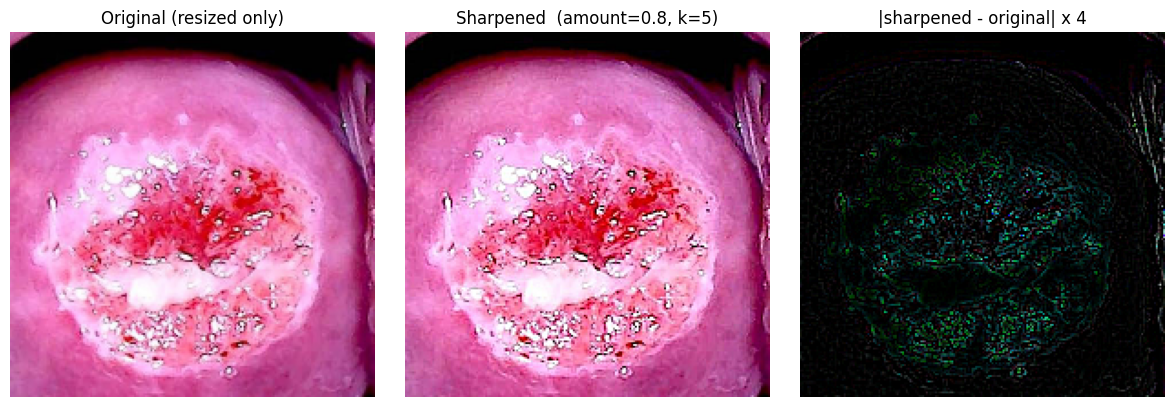


Harshness provenance check (pixel fractions, mean over the batch):
  any channel >= 255     : resized  3.186%  ->  after sharpen 14.976%  (x4.7)
  red channel >= 255     : resized  2.898%  ->  after sharpen 14.214%
  specular (V>=250,S<=25): resized  1.955%  ->  after sharpen  3.591%
  Detection bar = 0.05%: that is a VERY low bar -- at 0.05% of pixels
  clipping is trace level, so read the percentages above, not a verdict.
  -> trace clipping IS present before sharpening (3.186% of pixels):
     the dataset contributes that share (or an earlier step outside this
     notebook does) -- that is all this weak bar supports.
  -> Step 1 sharpening multiplies clipped pixels by ~4.7x: unsharp
     masking is a linear filter clipped to [0, 255]. DECISION NEEDED at
     SUITE level: this sharpening is SHARED across the 26-notebook suite,
     so either change it suite-wide or accept it as a suite-level
     limitation (recorded in the T6 caveats). This notebook cannot
     decide that alone.


In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation + harshness provenance
#   * The left panel is genuinely resize-only (X_resized[0], not the
#     already-sharpened stack); arrays are named X_sharp / X_resized.
#   * Clipping / specular provenance check -- are the blown reds and
#     specular highlights already in the DATASET, or introduced by
#     Step 1? Step 1 is a SUITE-LEVEL decision: this notebook reports
#     its effect but cannot change it alone.
# ============================================================
_CLIP_STATS = None


def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb          # caller passes the RESIZE-ONLY image
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


def _clip_provenance_stats():
    """Where does the harshness come from: the dataset or Step 1?

    Compares clipped-highlight / red-clip / specular fractions for the
    resize-only stack (X_resized) vs the sharpened stack (X_sharp).
    If the resize-only stack is already clipped, the harshness comes
    from the dataset/acquisition; if clipping appears only after
    sharpening, Step 1 is responsible (unsharp masking saturates at 255).
    The numbers are stored in _CLIP_STATS (quoted in the T6 caveats).
    """
    global _CLIP_STATS

    def _one(stack):
        any_c = float((stack >= 255).any(axis=-1).mean())
        red_c = float((stack[..., 0] >= 255).mean())
        spec = 0.0
        for im in stack:
            hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
            spec += float(((hsv[..., 2] >= AT_SPECULAR_V_MIN) &
                           (hsv[..., 1] <= AT_SPECULAR_S_MAX)).mean())
        return any_c, red_c, spec / max(len(stack), 1)

    r_any, r_red, r_spec = _one(X_resized)
    s_any, s_red, s_spec = _one(X_sharp)
    _CLIP_STATS = {"any_resized": r_any, "any_sharp": s_any,
                   "red_resized": r_red, "red_sharp": s_red}
    _mult = s_any / max(r_any, 1e-9)
    print("Harshness provenance check (pixel fractions, mean over the batch):")
    print(f"  any channel >= 255     : resized {100*r_any:6.3f}%  ->  after sharpen {100*s_any:6.3f}%  (x{_mult:.1f})")
    print(f"  red channel >= 255     : resized {100*r_red:6.3f}%  ->  after sharpen {100*s_red:6.3f}%")
    print(f"  specular (V>=250,S<=25): resized {100*r_spec:6.3f}%  ->  after sharpen {100*s_spec:6.3f}%")
    print("  Detection bar = 0.05%: that is a VERY low bar -- at 0.05% of pixels")
    print("  clipping is trace level, so read the percentages above, not a verdict.")
    if r_any > 0.0005:
        print(f"  -> trace clipping IS present before sharpening ({100*r_any:.3f}% of pixels):")
        print("     the dataset contributes that share (or an earlier step outside this")
        print("     notebook does) -- that is all this weak bar supports.")
    if s_any > r_any * 1.5:
        print(f"  -> Step 1 sharpening multiplies clipped pixels by ~{_mult:.1f}x: unsharp")
        print("     masking is a linear filter clipped to [0, 255]. DECISION NEEDED at")
        print("     SUITE level: this sharpening is SHARED across the 26-notebook suite,")
        print("     so either change it suite-wide or accept it as a suite-level")
        print("     limitation (recorded in the T6 caveats). This notebook cannot")
        print("     decide that alone.")
    print("  Note: this batch-level check needs the REAL dataset; on the synthetic")
    print("  fallback the numbers are not meaningful for acquisition quality.")


if len(X_sharp) > 0:
    # X_resized[0] is genuinely resize-only.
    show_sharpen_effect(img_rgb=X_resized[0])
    print()
    _clip_provenance_stats()
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# Cell 2.1 -- Adaptive Thresholding preprocessing pipeline (RGB)
#
# Output type: colour-enhanced uint8 RGB image (same shape as the
# input). Not a compression scheme; no byte stream. Pixels outside the
# analysis region are copied verbatim.
#
# Structure implemented here:
#  * MASKED LOCAL MEAN (normalised convolution): the local mean is
#    computed from FOV pixels ONLY -- blur(gray*F)/blur(F) -- so the
#    black background can no longer drag the mean down at the
#    tissue-to-background edge (the top-arc artefact). With nothing
#    masked this reduces to the classical adaptive threshold; the
#    agreement with cv2.adaptiveThreshold is checked in the sanity run.
#  * ANALYSIS REGION: FOV eroded by AT_FOV_ERODE_PX (kills the FOV edge
#    arc) MINUS the border-connected bright low-saturation strip (metal
#    speculum/instrument heuristic). W is zero outside it, so neither
#    the edge arc nor the instrument strip is ever enhanced.
#  * SIGN FIX: C is NEGATIVE. T = localMean - C, so a POSITIVE C LOWERS
#    the threshold and selects most tissue (the old C=+10 defaults
#    failed their own criteria: coverage 68.5%, noise 1.231). With a
#    negative C a pixel must be brighter than localMean + |C|: W is high
#    only on locally-bright structure.
#  * REGION CLEANUP: small connected components removed, specular
#    pixels excluded, BEFORE feathering into W.
#  * GAIN CUT: 0.8 -> 0.35 (input already sharpened in Step 1).
#  * Acceptance criteria (coverage of the ANALYSIS region, smooth-region
#    noise m9, in-region noise inside W >= 0.5) are checked explicitly
#    below -- NOT the validation scores.
# ============================================================

def _at_method_flag():
    """Map the AT_METHOD config string to the OpenCV flag."""
    if AT_METHOD == "gaussian":
        return cv2.ADAPTIVE_THRESH_GAUSSIAN_C
    elif AT_METHOD == "mean":
        return cv2.ADAPTIVE_THRESH_MEAN_C
    raise ValueError(f"AT_METHOD must be 'gaussian' or 'mean', got {AT_METHOD!r}")


def _gaussian_sigma_for_blocksize(bs):
    """The sigma cv2 uses internally for the Gaussian adaptive-threshold
    kernel (same formula as cv2.getGaussianKernel's default)."""
    return 0.3 * ((bs - 1) * 0.5 - 1) + 0.8


def specular_mask(img_rgb, v_min=None, s_max=None):
    """Specular/glare mask: bright AND low saturation (single source of
    truth; the validator reuses this function)."""
    v_min = AT_SPECULAR_V_MIN if v_min is None else v_min
    s_max = AT_SPECULAR_S_MAX if s_max is None else s_max
    hsv = cv2.cvtColor(np.asarray(img_rgb), cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= v_min) & (hsv[..., 1] <= s_max)).astype(bool)


def compute_fov_mask(img_rgb, thr=15):
    """Field-of-view mask: brightness threshold + morphology + largest
    component + convex-hull fill. Computed from the RESIZE-ONLY image.
    Defined here so it can be computed BEFORE Step 2 and passed
    everywhere (pipeline, validator, region-split tables)."""
    img = np.asarray(img_rgb)
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov


def instrument_mask(img_rgb, fov_mask, v_min=None, s_max=None, min_area=None):
    """Metal speculum / instrument strip mask (HEURISTIC).

    Candidates: bright AND low saturation (V >= v_min, S <= s_max),
    morphologically closed. A candidate component is kept only if it
    TOUCHES the frame border or the outside-FOV boundary (instruments
    enter the frame from outside; interior bright low-saturation blobs
    are acetowhite tissue or glare and are NOT instrument). The kept
    components are dilated. This is tunable and imperfect: check the
    W maps -- the strip appears in the stage figure if the heuristic
    misses it."""
    v_min = AT_INSTR_V_MIN if v_min is None else v_min
    s_max = AT_INSTR_S_MAX if s_max is None else s_max
    min_area = AT_INSTR_MIN_AREA if min_area is None else min_area
    img = np.asarray(img_rgb)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    cand = ((hsv[..., 2] >= v_min) & (hsv[..., 1] <= s_max)).astype(np.uint8)
    cand = cv2.morphologyEx(cand, cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    keep = np.zeros(img.shape[:2], dtype=bool)
    if n <= 1:
        return keep
    fov = np.asarray(fov_mask, dtype=bool)
    border = np.zeros(img.shape[:2], dtype=np.uint8)
    b = 3
    border[:b, :] = 1; border[-b:, :] = 1; border[:, :b] = 1; border[:, -b:] = 1
    # Round 5: wider dilation (15px, was 9) so the left vertical strip --
    # which sits just inside the FOV edge -- is caught as border-connected.
    touch = cv2.dilate(border | (~fov).astype(np.uint8),
                       cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
                       ).astype(bool)
    for li in range(1, n):
        comp = lab == li
        if stats[li, cv2.CC_STAT_AREA] >= min_area and (comp & touch).any():
            keep |= comp
    keep = cv2.dilate(keep.astype(np.uint8),
                      cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
                      ).astype(bool)
    return keep


def compute_analysis_region(fov_mask, img_rgb=None):
    """ANALYSIS REGION for the threshold map: the FOV eroded by
    AT_FOV_ERODE_PX (kills the black-background-to-tissue edge arc)
    minus the border-connected instrument/speculum strip.
    Returns (region, instrument_mask, n_instrument_px_inside_region)."""
    fov = np.asarray(fov_mask, dtype=bool)
    e = int(AT_FOV_ERODE_PX)
    if e > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * e + 1, 2 * e + 1))
        # borderValue=0: strict erosion -- the analysis region is pulled back
        # from the IMAGE border too (a FOV running to the frame edge gets no
        # special treatment), so no analysis pixel hugs the frame edge.
        reg = cv2.erode(fov.astype(np.uint8), k,
                        borderType=cv2.BORDER_CONSTANT, borderValue=0).astype(bool)
    else:
        reg = fov.copy()
    instr = np.zeros(fov.shape, dtype=bool)
    n_instr = 0
    if AT_EXCLUDE_INSTRUMENT and img_rgb is not None:
        instr = instrument_mask(img_rgb, fov)
        n_instr = int((instr & reg).sum())
        reg = reg & ~instr
    return reg, instr, n_instr


def _unmasked_local_mean(gray_s, bs):
    """Classical (unmasked) local mean, used only for the equivalence
    check against cv2.adaptiveThreshold."""
    g = gray_s.astype(np.float32)
    if AT_METHOD == "gaussian":
        return cv2.GaussianBlur(g, (bs, bs), _gaussian_sigma_for_blocksize(bs))
    return cv2.boxFilter(g, -1, (bs, bs))


def _cv2_equivalence_check(gray_s, bs, c_v):
    """Agreement between the manual unmasked threshold and
    cv2.adaptiveThreshold (same pre-blurred grayscale, same C). The
    normalised-convolution implementation must reduce to the classical
    one when nothing is masked; only rounding-level differences remain."""
    manual = gray_s.astype(np.float32) > (_unmasked_local_mean(gray_s, bs) - c_v)
    cvt = cv2.adaptiveThreshold(gray_s, 255, _at_method_flag(),
                                cv2.THRESH_BINARY, bs, c_v).astype(bool)
    return float((manual == cvt).mean())


def global_boost_preprocess(img_rgb, gain=None, sigma=None):
    """W = 1 GLOBAL-BOOST control.

    The SAME detail-band enhancement as the AT pipeline, applied
    uniformly: no thresholding, no region selection, no FOV gating.
    Together with SharpenOnly it answers the key question: does
    adaptive thresholding contribute anything beyond a global detail
    boost? At gain = AT_ENHANCE_GAIN x mean W it is the GAIN-MATCHED
    control that isolates what region selection itself contributes."""
    gain_v = float(gain if gain is not None else AT_ENHANCE_GAIN)
    sig_v  = float(sigma if sigma is not None else AT_ENHANCE_SIGMA)
    img = np.asarray(img_rgb)
    if img.dtype != np.uint8:
        img = np.clip(img, 0, 255).astype(np.uint8)
    ks = max(3, int(2 * round(3 * sig_v) + 1))
    base = cv2.GaussianBlur(img, (ks, ks), sig_v)
    detail = img.astype(np.float32) - base.astype(np.float32)
    return np.clip(img.astype(np.float32) + gain_v * detail, 0, 255).astype(np.uint8)


def _noise_ratio_local(original, processed, fov_mask, sigma=1.5):
    """MAD-based noise ratio (out/in) on the 30% SMOOTHEST pixels. Same
    estimator as the validator's m9, kept here so the Part A acceptance
    check is self-contained. NOTE: W sits on edges, so this estimator
    barely sees the enhanced region -- the in-region ratio below is the
    binding noise check."""
    f = np.asarray(fov_mask, dtype=bool)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY).astype(np.float32)
    hp_o = g_o - cv2.GaussianBlur(g_o, (0, 0), sigma)
    hp_p = g_p - cv2.GaussianBlur(g_p, (0, 0), sigma)
    gm = np.hypot(cv2.Sobel(g_o, cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o, cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if not smooth.any():
        return float('nan')
    n_o = 1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth])))
    n_p = 1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth])))
    return float(n_p / max(n_o, 1e-9))


def _noise_ratio_in_region(original, processed, region_mask, sigma=1.5, min_px=200):
    """MAD high-pass noise ratio (out/in) measured INSIDE the given
    region (e.g. W >= 0.5). The smooth-region estimator samples the 30%
    smoothest pixels, which barely overlaps the enhanced region, so the
    noise criterion needs this region-restricted view. Returns NaN when
    the region is smaller than min_px, or when the ORIGINAL region has
    no measurable noise (MAD*1.4826 below the 0.25-level floor): a ratio
    against a zero denominator is meaningless, not 'infinitely bad'."""
    r = np.asarray(region_mask, dtype=bool)
    if int(r.sum()) < min_px:
        return float('nan')
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY).astype(np.float32)
    hp_o = g_o - cv2.GaussianBlur(g_o, (0, 0), sigma)
    hp_p = g_p - cv2.GaussianBlur(g_p, (0, 0), sigma)
    n_o = 1.4826 * np.median(np.abs(hp_o[r] - np.median(hp_o[r])))
    if n_o < 0.25:
        return float('nan')
    n_p = 1.4826 * np.median(np.abs(hp_p[r] - np.median(hp_p[r])))
    return float(n_p / max(n_o, 1e-9))


def adaptive_threshold_preprocess(img_rgb, return_artefacts=False, fov_mask=None,
                                  block_size=None, c=None, gain=None,
                                  soft_sigma=None, remove_small_area=None,
                                  exclude_specular=None):
    """Adaptive Thresholding preprocessing pipeline (colour-preserving).

    Steps
    -----
    1. Grayscale + light Gaussian pre-blur so single-pixel noise does
       not punch holes in the local statistics.
    2. MASKED local mean via normalised convolution: the local mean is
       computed from FOV pixels ONLY, blur(gray*F)/blur(F), so the black
       background does not drag the mean down at the tissue edge. With
       nothing masked this equals the classical adaptive threshold.
    3. Threshold T = localMean - C with the default NEGATIVE C: a pixel
       is selected only when meaningfully brighter than its
       neighbourhood. A positive C would LOWER the threshold and select
       most smooth tissue instead (the original bug).
    4. Region cleanup: connected components < AT_REMOVE_SMALL_AREA px
       removed; specular pixels excluded.
    5. Feather B (sigma = AT_SOFT_SIGMA) into a soft region weight W in
       [0, 1]; W is zeroed outside the ANALYSIS REGION (FOV eroded by
       AT_FOV_ERODE_PX minus the border-connected instrument strip).
    6. Colour-preserving local contrast enhancement:
           detail = img - GaussianBlur(img, AT_ENHANCE_SIGMA)
           out    = img + AT_ENHANCE_GAIN * W * detail
       All three channels share the same weight, so hue relations are
       preserved. Pixels outside the analysis region are copied
       verbatim.

    FOV handling: `fov_mask=None` means "compute it from this image"
    (compute_fov_mask) -- NOT "everything is inside the FOV". The
    optional per-call overrides (block_size, c, gain, ...) exist for the
    ablation grid and the gain sweep; defaults come from the config.

    Deterministic: no randomness anywhere in the path.
    """
    img = np.asarray(img_rgb)
    if img.dtype != np.uint8:
        img = np.clip(img, 0, 255).astype(np.uint8)

    bs    = int(block_size if block_size is not None else AT_BLOCK_SIZE)
    c_v   = float(c if c is not None else AT_C)
    gain_v = float(gain if gain is not None else AT_ENHANCE_GAIN)
    sig_v = float(soft_sigma if soft_sigma is not None else AT_SOFT_SIGMA)
    rsa   = int(remove_small_area if remove_small_area is not None else AT_REMOVE_SMALL_AREA)
    exspec = bool(exclude_specular if exclude_specular is not None else AT_EXCLUDE_SPECULAR)

    if fov_mask is None:
        fov_mask = compute_fov_mask(img)          # compute, don't assume all-ones
    else:
        fov_mask = np.asarray(fov_mask, dtype=bool)

    # Analysis region: FOV eroded + instrument strip removed
    analysis, instr_m, n_instr = compute_analysis_region(fov_mask, img)

    # (1) grayscale + pre-blur
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    k = int(AT_PREBLUR_KSIZE)
    if k > 1:
        if k % 2 == 0:
            k += 1
        gray_s = cv2.GaussianBlur(gray, (k, k), 0)
    else:
        gray_s = gray

    # (2) masked local mean via normalised convolution (FOV pixels only)
    if bs % 2 == 0:
        bs += 1
    bs = max(3, bs)
    M = fov_mask.astype(np.float32)
    I = gray_s.astype(np.float32) * M
    if AT_METHOD == "gaussian":
        sig = _gaussian_sigma_for_blocksize(bs)
        num = cv2.GaussianBlur(I, (bs, bs), sig)
        den = cv2.GaussianBlur(M, (bs, bs), sig)
    else:
        num = cv2.boxFilter(I, -1, (bs, bs), normalize=False)
        den = cv2.boxFilter(M, -1, (bs, bs), normalize=False)
    local_mean = num / np.maximum(den, 1e-6)

    # (3) threshold, restricted to the analysis region
    binary_arr = (gray_s.astype(np.float32) > (local_mean - c_v)) & analysis

    # (4) region cleanup BEFORE feathering
    bin_bool = binary_arr
    n_small_removed = 0
    n_spec_excluded = 0
    if rsa > 0:
        n_lab, lab, stats, _ = cv2.connectedComponentsWithStats(
            bin_bool.astype(np.uint8), connectivity=8)
        keep = np.zeros(n_lab, dtype=bool)
        for li in range(1, n_lab):
            keep[li] = stats[li, cv2.CC_STAT_AREA] >= rsa
        small_removed = bin_bool & ~keep[lab]
        n_small_removed = int(small_removed.sum())
        bin_bool = bin_bool & keep[lab]
    if exspec:
        spec = specular_mask(img)
        n_spec_excluded = int((bin_bool & spec).sum())
        bin_bool = bin_bool & ~spec
    binary = bin_bool.astype(np.uint8) * 255

    # (5) feathered soft region weight (inside the ANALYSIS REGION only)
    W = gaussian_filter(binary.astype(np.float32) / 255.0, sigma=sig_v)
    W = np.clip(W, 0.0, 1.0)
    W[~analysis] = 0.0

    # (6) guided local contrast enhancement (colour preserved)
    ks = max(3, int(2 * round(3 * float(AT_ENHANCE_SIGMA)) + 1))
    base = cv2.GaussianBlur(img, (ks, ks), float(AT_ENHANCE_SIGMA))
    detail = img.astype(np.float32) - base.astype(np.float32)
    proc = np.clip(img.astype(np.float32)
                   + gain_v * W[..., None] * detail,
                   0, 255).astype(np.uint8)

    # outside the analysis region the output is the input, verbatim
    proc[~analysis] = img[~analysis]

    if not return_artefacts:
        return proc

    n_ana = int(analysis.sum())
    region_inw = (W >= 0.5) & analysis
    return {
        'img_original':   img,
        'img_processed':  proc,
        'gray':           gray,
        'gray_blurred':   gray_s,
        'binary_map':     binary,
        'soft_mask':      W,
        'fov_mask':       fov_mask,
        'analysis_region': analysis,
        'instrument_mask': instr_m,
        'n_instrument_px': n_instr,
        # coverage AFTER cleanup, as a fraction of the ANALYSIS region --
        # this is the number the acceptance criterion applies to.
        'region_coverage': float((bin_bool & analysis).sum() / max(n_ana, 1)),
        'mean_W':         float(W[analysis].mean()) if n_ana else float('nan'),
        'region_inw_px':  int(region_inw.sum()),
        'nr_in_abs':      _noise_ratio_in_region(img, proc, region_inw),
        'n_small_removed': n_small_removed,
        'n_specular_excluded': n_spec_excluded,
    }


# ---- Sanity check + acceptance criteria on the first image ----
if len(X_sharp) > 0:
    art0 = adaptive_threshold_preprocess(X_sharp[0], return_artefacts=True)
    _fov0 = art0['fov_mask']
    _ana0 = art0['analysis_region']
    _n_out = int((~_fov0).sum())
    print("Adaptive Thresholding preprocessing sanity check (image 0):")
    print(f"  FOV = {int(_fov0.sum())} px ({100*_fov0.mean():.1f}% of frame); "
          f"ANALYSIS region = {int(_ana0.sum())} px "
          f"({100*_ana0.sum()/max(int(_fov0.sum()),1):.1f}% of FOV) "
          f"= FOV eroded {AT_FOV_ERODE_PX} px"
          + (f" minus instrument strip ({art0['n_instrument_px']} px removed)"
             if AT_EXCLUDE_INSTRUMENT else ""))
    print(f"  img_original  shape={art0['img_original'].shape} dtype={art0['img_original'].dtype}")
    print(f"  img_processed shape={art0['img_processed'].shape} dtype={art0['img_processed'].dtype}")
    _bs_chk = max(3, int(AT_BLOCK_SIZE))
    _agree = _cv2_equivalence_check(art0['gray_blurred'], _bs_chk, float(AT_C))
    print(f"  implementation check vs cv2.adaptiveThreshold (nothing masked): "
          f"{100*_agree:.2f}% agreement (rounding-level differences only)")
    print(f"  binary_map    selected fraction of the ANALYSIS region (after cleanup) = "
          f"{100 * art0['region_coverage']:.2f}%"
          f"   [criterion: {AT_COVERAGE_LO:.0%}-{AT_COVERAGE_HI:.0%} -> "
          f"{'OK' if AT_COVERAGE_LO <= art0['region_coverage'] <= AT_COVERAGE_HI else 'OUT OF RANGE'}]")
    print(f"  cleanup: {art0['n_small_removed']} px removed as small components, "
          f"{art0['n_specular_excluded']} px excluded as specular")
    print(f"  soft_mask W   mean={art0['mean_W']:.3f}  std={art0['soft_mask'][_ana0].std():.3f}")
    _outside_equal = np.array_equal(art0['img_processed'][~_fov0],
                                    art0['img_original'][~_fov0])
    _outana_equal = np.array_equal(art0['img_processed'][~_ana0],
                                   art0['img_original'][~_ana0])
    print(f"  outside-FOV pixels identical to input: {_outside_equal}  (must be True)")
    print(f"  outside-ANALYSIS pixels identical to input: {_outana_equal}  (must be True)")
    _nr0 = _noise_ratio_local(art0['img_original'], art0['img_processed'], _fov0)
    print(f"  noise ratio m9 (smooth regions, out/in) = {_nr0:.3f}   "
          f"[criterion <= {AT_NOISE_RATIO_MAX} -> "
          f"{'OK' if _nr0 <= AT_NOISE_RATIO_MAX else 'OUT OF RANGE'}]")
    _rin0 = art0['region_inw_px']
    if np.isnan(art0['nr_in_abs']):
        print(f"  noise ratio INSIDE W>=0.5: undefined (region has only {_rin0} px; "
              f"min 200 px) -- check coverage")
    else:
        print(f"  noise ratio INSIDE W>=0.5 (abs) = {art0['nr_in_abs']:.3f}  "
              f"(region = {_rin0} px). Round 5: the ABSOLUTE in-region noise ratio is")
        print(f"  reported (x INPUT noise, cap {AT_NOISE_INW_ABS_MAX}); the")
        print(f"  ablation grid reports the ABSOLUTE in-region ratio (cap 1.20, reported)")
        print(f"  and the legacy GM-relative ratio (reported only).")
    mse = np.mean((art0['img_original'].astype(np.float64)
                   - art0['img_processed'].astype(np.float64)) ** 2)
    psnr = 10 * np.log10(255.0 ** 2 / mse) if mse > 1e-10 else float('inf')
    print(f"  PSNR (proc vs orig) = {psnr:.2f} dB  "
          f"(enhancement is local -> high fidelity is expected)")
    print("  NOTE: parameters are JUDGED on the coverage/noise criteria above;")
    print("        whether they PASS is printed here and in the Part B ablation")
    print("        grid -- they are NOT judged on PSNR/SSIM/dE.")


Adaptive Thresholding preprocessing sanity check (image 0):
  FOV = 37157 px (92.9% of frame); ANALYSIS region = 30683 px (82.6% of FOV) = FOV eroded 9 px minus instrument strip (0 px removed)
  img_original  shape=(200, 200, 3) dtype=uint8
  img_processed shape=(200, 200, 3) dtype=uint8
  implementation check vs cv2.adaptiveThreshold (nothing masked): 98.89% agreement (rounding-level differences only)
  binary_map    selected fraction of the ANALYSIS region (after cleanup) = 24.24%   [criterion: 15%-35% -> OK]
  cleanup: 772 px removed as small components, 987 px excluded as specular
  soft_mask W   mean=0.242  std=0.312
  outside-FOV pixels identical to input: True  (must be True)
  outside-ANALYSIS pixels identical to input: True  (must be True)
  noise ratio m9 (smooth regions, out/in) = 1.086   [criterion <= 1.1 -> OK]
  noise ratio INSIDE W>=0.5 (abs) = 1.225  (region = 7142 px). Round 5: the ABSOLUTE in-region noise ratio is
  reported (x INPUT noise, cap 1.2); the
  ablation gr

In [6]:
# ============================================================
# Cell 2.2 -- Visualise Adaptive Thresholding preprocessing stages
#   * Captions are built from the CONFIG (no hardcoded literals) and
#     kept SHORT (the review flagged overlapping titles).
#   * The binary-map panel draws the analysis-region boundary (magenta):
#     anything outside it (FOV edge arc, instrument strip) is never
#     selected.
#   * Shared dHash clustering helper (reused by Part B Step 4.1).
# ============================================================

def dhash_hamming_clusters(images, thresh=4):
    """Cluster frames by dHash Hamming distance <= thresh (near-duplicates).
    Returns an int array cluster_ids (one entry per image). Shared by the
    Part A per-unique figure and Part B Step 4.1."""
    hs = []
    for im in images:
        g = cv2.resize(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (9, 8),
                       interpolation=cv2.INTER_AREA).astype(np.int16)
        hs.append((g[:, 1:] > g[:, :-1]).ravel())
    n = len(hs)
    cluster_ids = np.full(n, -1, dtype=int)
    next_id = 0
    for i in range(n):
        if cluster_ids[i] >= 0:
            continue
        cluster_ids[i] = next_id
        for j in range(i + 1, n):
            if cluster_ids[j] < 0 and (hs[i] != hs[j]).sum() <= thresh:
                cluster_ids[j] = next_id
        next_id += 1
    return cluster_ids


def show_at_stages(rgb_image, title=""):
    """One-row figure: original / gray / binary map / soft W / output / diff."""
    art = adaptive_threshold_preprocess(rgb_image, return_artefacts=True)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.ravel()

    axes[0].imshow(art['img_original'])
    axes[0].set_title("Step 0 - Sharpened input")
    axes[0].axis('off')

    axes[1].imshow(art['gray'], cmap='gray', vmin=0, vmax=255)
    axes[1].set_title("Step 2.1 - Grayscale (pre-blurred)")
    axes[1].axis('off')

    im_b = axes[2].imshow(art['binary_map'], cmap='gray', vmin=0, vmax=255)
    axes[2].set_title(f"AT binary map ({AT_METHOD}, b={AT_BLOCK_SIZE}, C={AT_C:g})\n"
                      f"selected {100 * art['region_coverage']:.1f}% of analysis region "
                      f"(target {AT_COVERAGE_LO:.0%}-{AT_COVERAGE_HI:.0%}); "
                      f"magenta = analysis boundary")
    axes[2].axis('off')
    _cnts, _ = cv2.findContours(art['analysis_region'].astype(np.uint8),
                                cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in _cnts:
        pts = cnt.squeeze(1)
        if pts.ndim == 1:
            continue
        axes[2].plot(pts[:, 0], pts[:, 1], '-m', linewidth=0.8, alpha=0.9)
    plt.colorbar(im_b, ax=axes[2], fraction=0.046, pad=0.04)

    im_w = axes[3].imshow(art['soft_mask'], cmap='viridis', vmin=0, vmax=1)
    axes[3].set_title(f"Soft W (feather sigma={AT_SOFT_SIGMA})\nmean={art['mean_W']:.3f}")
    axes[3].axis('off')
    plt.colorbar(im_w, ax=axes[3], fraction=0.046, pad=0.04)

    axes[4].imshow(art['img_processed'])
    axes[4].set_title(f"Colour-enhanced output\n(gain={AT_ENHANCE_GAIN})")
    axes[4].axis('off')

    # |Original - Processed| x 3 (zero outside the analysis region)
    diff_rgb = np.abs(art['img_original'].astype(np.float32)
                      - art['img_processed'].astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    diff_gray[~art['analysis_region']] = 0.0
    diff_scaled = diff_gray * 3.0
    p99 = float(np.percentile(diff_scaled[art['analysis_region']], 99)) \
        if art['analysis_region'].any() else 1e-6
    p99 = max(p99, 1e-6)
    diff_norm = np.clip(diff_scaled / p99, 0.0, 1.0)
    axes[5].imshow(diff_norm, cmap='gray', vmin=0.0, vmax=1.0)
    axes[5].set_title("|Original - Processed| x 3\n(outside analysis region = 0)")
    axes[5].axis('off')

    fig.suptitle(f"Adaptive Thresholding Preprocessing Stages - {title}",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig



# Round 6: the dHash-group 'up to 7 panels' figure was REMOVED -- the groups
# are just the augmentation variants of one image (AAM1, N=1), so a
# per-group figure adds no information. See Fig B (Step 4.5) for the
# variant-type panels (flipped/noisy/rotated/base) instead.

In [7]:
# ============================================================
# Cell 2.3 -- Lesion-level diagnostics (auto-skip).
#   * Zoomed lesion crops: original (resized) / sharpen-only input / AT
#     output, with the lesion contour overlaid.
#   * Histogram of the soft weight W inside vs outside the lesion.
# If no lesion masks matched, a path/stem diagnostic is printed and the
# cell skips gracefully (the loader's diagnostics show the first stems
# and mask filenames; a MISSING masks/ folder now warns loudly and
# scans the image folder for *.json COCO annotations).
# ============================================================
_n_frames_with_lesion = int(masks_raw.any((1, 2)).sum()) if len(masks_raw) else 0
_has_lesions = bool(len(X_sharp) > 0 and _n_frames_with_lesion > 0)

if not _has_lesions:
    print("No lesion masks available -> lesion-level diagnostics SKIPPED (auto-skip).")
    print("  Checklist to fix mask matching:")
    print(f"    - masks matched via the masks/ folder: {n_with_mask}/{len(X_sharp)}; "
          f"frames with a lesion mask: {_n_frames_with_lesion}/{len(masks_raw)}; "
          f"MASKS_SUBDIR = {MASKS_SUBDIR!r}")
    print("    - if the masks/ folder does not exist at all, the loader printed a")
    print("      [WARN] block and scanned the image folder for *.json (COCO exports")
    print("      ship polygon annotations, not PNG masks)")
    print("    - mask filename stems must match image stems (case-insensitive;")
    print("      '_mask' / '-mask' / 'mask_' variants are tried automatically)")
    print("    - matching strips ' - Copy (N)' suffixes and '.rf.<hash>' markers;")
    print("      the loader diagnostics also census mask file types (raster PNG")
    print("      vs polygon/COCO annotation JSON -- JSONs cannot load as masks)")
    if len(paths_raw) > 0:
        print(f"    - first image stems: "
              f"{[os.path.splitext(os.path.basename(p))[0] for p in paths_raw[:5]]}")
    print("  Once masks load, this cell produces the zoomed crops and the")
    print("  inside/outside-lesion W histogram.")
else:
    _areas = masks_raw.reshape(len(masks_raw), -1).sum(axis=1)
    _sel = [int(i) for i in np.argsort(_areas)[::-1] if _areas[i] > 0][:3]

    # ---- Figure 1: zoomed lesion crops ----
    fig_l, axes_l = plt.subplots(len(_sel), 3, figsize=(11, 3.6 * len(_sel)), squeeze=False)
    for r, i in enumerate(_sel):
        ys, xs = np.where(masks_raw[i])
        y0, y1 = max(ys.min() - 12, 0), min(ys.max() + 12, IMG_SIZE)
        x0, x1 = max(xs.min() - 12, 0), min(xs.max() + 12, IMG_SIZE)
        art_i = adaptive_threshold_preprocess(X_sharp[i], return_artefacts=True)
        panels = [(X_resized[i], "Original (resized only)"),
                  (X_sharp[i], "Sharpen-only input (Step 1)"),
                  (art_i['img_processed'], "AT output (Step 2)")]
        for c, (im, ttl) in enumerate(panels):
            ax = axes_l[r, c]
            ax.imshow(im[y0:y1, x0:x1])
            contour, _ = cv2.findContours(masks_raw[i].astype(np.uint8),
                                          cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contour:
                pts = cnt.squeeze(1)
                if pts.ndim == 1:
                    continue
                ax.plot(pts[:, 0] - x0, pts[:, 1] - y0, '-c', linewidth=1.2)
            ax.set_title(ttl if r == 0 else "", fontsize=10)
            ax.axis('off')
        axes_l[r, 0].set_ylabel(f"img {i}\nlesion {int(_areas[i])} px", fontsize=9)
    fig_l.suptitle("Zoomed lesion crops (cyan = clinician lesion contour)",
                   fontsize=13, fontweight='bold')
    plt.tight_layout()
    fig_l.savefig(os.path.join(SAVE_DIR, "fig_lesion_crops.png"), dpi=150)
    plt.show()
    print(f"Saved {SAVE_DIR}/fig_lesion_crops.png")

    # ---- Figure 2: W inside vs outside the lesion + lesion-aware W summary ----
    # (this printed summary is the only direct selectivity readout --
    #  it quantifies whether W concentrates inside the lesion.)
    w_in_all, w_out_all = [], []
    _les_px = _les_in_reg = _reg_px = _reg_is_les = 0
    for i in np.where(_areas > 0)[0]:
        art_i = adaptive_threshold_preprocess(X_sharp[i], return_artefacts=True)
        _W_i, _fov_i = art_i['soft_mask'], art_i['fov_mask']
        lm = masks_raw[i] & _fov_i
        if lm.any():
            w_in_all.append(_W_i[lm])
            _les_px += int(lm.sum())
            _les_in_reg += int((_W_i[lm] >= 0.5).sum())
        outside = _fov_i & ~masks_raw[i]
        if outside.any():
            w_out_all.append(_W_i[outside])
        reg = (_W_i >= 0.5) & _fov_i
        _reg_px += int(reg.sum())
        _reg_is_les += int((reg & lm).sum())
    w_in = np.concatenate(w_in_all) if w_in_all else np.array([])
    w_out = np.concatenate(w_out_all) if w_out_all else np.array([])
    fig_h, ax_h = plt.subplots(1, 1, figsize=(8, 4.2))
    bins = np.linspace(0, 1, 41)
    ax_h.hist(w_out, bins=bins, alpha=0.6, density=True, color='steelblue',
              label=f"outside lesion (mean={w_out.mean():.3f})" if w_out.size else "outside")
    ax_h.hist(w_in, bins=bins, alpha=0.6, density=True, color='darkorange',
              label=f"inside lesion (mean={w_in.mean():.3f})" if w_in.size else "inside")
    ax_h.set_xlabel("soft region weight W")
    ax_h.set_ylabel("density")
    ax_h.set_title("W inside vs outside the lesion\n"
                   "(lesion-selective behaviour = orange mass shifted right)")
    ax_h.legend()
    ax_h.grid(alpha=0.3)
    plt.tight_layout()
    fig_h.savefig(os.path.join(SAVE_DIR, "fig_W_inside_outside_lesion.png"), dpi=150)
    plt.show()
    print(f"Saved {SAVE_DIR}/fig_W_inside_outside_lesion.png")
    if w_in.size and w_out.size:
        _ratio = float(w_in.mean() / max(w_out.mean(), 1e-9))
        _verdict = ("lesion-focused" if _ratio > 1.05 else
                    "NOT lesion-selective" if _ratio < 0.95 else
                    "no meaningful selectivity")
        print("  Lesion-aware W summary (FOV-restricted, all lesion frames):")
        print(f"    mean W inside lesion  = {w_in.mean():.3f}")
        print(f"    mean W outside lesion = {w_out.mean():.3f}")
        print(f"    selectivity ratio in/out = {_ratio:.2f}  -> {_verdict}")
        print(f"    lesion px covered by the W>=0.5 region: {_les_in_reg}/{_les_px} "
              f"= {100.0 * _les_in_reg / max(_les_px, 1):.1f}%")
        print(f"    W>=0.5 region that is lesion: {_reg_is_les}/{_reg_px} "
              f"= {100.0 * _reg_is_les / max(_reg_px, 1):.1f}% "
              "(the rest of the region is non-lesion tissue)")
        if _ratio <= 1.05:
            print("    => W does NOT concentrate inside the lesion; do not present the")
            print("       region as lesion-selective (see the ablation grid for larger")
            print("       windows and the zoomed W comparison).")


No lesion masks available -> lesion-level diagnostics SKIPPED (auto-skip).
  Checklist to fix mask matching:
    - masks matched via the masks/ folder: 0/16; frames with a lesion mask: 0/16; MASKS_SUBDIR = 'masks'
    - if the masks/ folder does not exist at all, the loader printed a
      [WARN] block and scanned the image folder for *.json (COCO exports
      ship polygon annotations, not PNG masks)
    - mask filename stems must match image stems (case-insensitive;
      '_mask' / '-mask' / 'mask_' variants are tried automatically)
    - matching strips ' - Copy (N)' suffixes and '.rf.<hash>' markers;
      the loader diagnostics also census mask file types (raster PNG
      vs polygon/COCO annotation JSON -- JSONs cannot load as masks)
    - first image stems: ['AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b139e8ac7 - Copy (2)', 'AAM1_flipped_0_jpg.rf.b49b5343637a78d19f45c3c0198e908b - Copy (2)', 'AAM1_noisy_0_jpg.rf.3475828beb26d82e3a050ba9be2213c9 - Copy (2)', 'AAM1_noisy_1_jpg.r

# Bridge — hand off Adaptive Thresholding preprocessing to the validation part

The validation part expects five variables from the preprocessing part:

| Name        | Meaning                                   | Source in this notebook                  |
|-------------|-------------------------------------------|------------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | `X_sharp` from the loader (one copy)     |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | `X_resized` from the loader — NO reload, and no reuse of the sharpened stack under a second name |
| `image_ids` | unique id per variant                     | sequential `img_NNNN` (N = md5-unique images) |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader              |
| `patient`   | patient id (OPTIONAL)                     | `None`                                   |

We also register the technique:

* `AT_DEFAULTS` — empty dict (the pipeline uses fixed module-level config; **no tuning on a single frame set**).
* `at_process(img, params, seed, fov_mask=None) -> uint8 RGB image` — wraps
  `adaptive_threshold_preprocess(img, return_artefacts=False)`.
  The FOV mask is computed before Step 2 (Step 4.1) and passed here via
  `fov_mask=fov[i]` from the validator, so the cached processed images
  and the region-split tables are guaranteed to share the same FOV.
  When `fov_mask=None` the FOV is computed from the image itself — it
  no longer defaults to "the whole frame is FOV".
* Determinism: the pipeline is fully deterministic (no random
  components), so the same input always yields the same output; the
  `seed` parameter is accepted for API compatibility and ignored.


In [8]:
# ============================================================
# Bridge -- hand Adaptive Thresholding preprocessing to the
# validation part.
#   * X_base comes from X_sharp, the validator's X_raw comes from
#     X_resized: no duplicate dataset reload, no synthetic rebuild, and
#     no array reused under a misleading name.
#   * at_process applies the FOV (computed here if not passed).
# ============================================================

# --- Step-2 input stack becomes the validator's X_base ---
X_base = X_sharp.copy()                     # sharpened, 200x200, uint8 RGB
X_raw  = X_resized.copy()                   # resize-only (FOV source + RawResized reference)
masks  = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
print(f"Unit of analysis: N=1 ({len(X_base)} augmented variants of AAM1) "
      f"(byte-identical copies were dropped in the loader).")

# ---- Adaptive Thresholding wrapper for the validator --------------------
AT_DEFAULTS = {}

def at_process(img, params=None, seed=0, fov_mask=None):
    """Adaptive Thresholding preprocessing, exposed to the validator.

    Signature: at_process(img_uint8_RGB, params_dict, seed[, fov_mask]) -> uint8 RGB.
    `params` is accepted for API compatibility but ignored (the pipeline
    uses fixed module-level configuration; no tuning on a single frame set).
    `seed` is accepted for API compatibility and ignored: the pipeline is
    fully deterministic.

    Pass the precomputed FOV mask (Step 4.1) so the cached processed
    images and the region-split tables share the exact same FOV. If
    None, the FOV is computed from the image itself -- it is NEVER
    silently replaced by "the whole frame".
    """
    if fov_mask is None:
        fov_mask = compute_fov_mask(img)
    return adaptive_threshold_preprocess(img, return_artefacts=False,
                                         fov_mask=fov_mask)

# Quick smoke test on the first image
_sm = at_process(X_base[0], AT_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"at_process smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(at_process(X_base[0], AT_DEFAULTS, seed=12345), _sm), \
    "at_process is not deterministic for the same seed"
# FOV consistency: wrapper-internal FOV == explicit compute_fov_mask
assert np.array_equal(at_process(X_base[0], AT_DEFAULTS, seed=1,
                                 fov_mask=compute_fov_mask(X_base[0])), _sm), \
    "at_process internal FOV differs from compute_fov_mask(X_base[0])"
print(f"at_process() wrapper ready  |  AT_DEFAULTS = {AT_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int) - X_base[0].astype(int)).mean():.3f}  |  "
      f"FOV coverage of frame = {100 * compute_fov_mask(X_base[0]).mean():.1f}%")


Bridge ready | X_base (sharpened) = (16, 200, 200, 3) uint8 | X_raw (resize-only) = (16, 200, 200, 3) uint8 | image_ids = 16 (all unique) | masks = (16, 200, 200) (0/16 have a lesion) | SYNTHETIC_MODE = False
Unit of analysis: N=1 (16 augmented variants of AAM1) (byte-identical copies were dropped in the loader).
at_process() wrapper ready  |  AT_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=0.708  |  FOV coverage of frame = 92.9%


# Part B — Validation: table-only metrics + figures, 11 metrics

**Unit of analysis (round 4 — N=1 REFRAME).** The T5 table lists all 16
md5-unique files, and every stem starts with `AAM1_` (`flipped_0`,
`noisy_0–4`, `rotated_1–4`, each in two `.rf.<hash>` versions). The
128-file export is therefore **16 augmentation variants of ONE source
image**, each repeated as 8 byte-identical copies. This is a
**single-image case study**, not a sample of 16.

The "95% CI" columns in T1 / T7 are **variant-spread intervals**
(bootstrap over the 16 augmented variants of AAM1), NOT population
confidence intervals — they quantify how stable the pipeline is to
flip/noise/rotation, not how it generalises across patients. No
p-values, no robustness or population claims. The 16 variants are an
**augmentation-robustness test** (see the equivariance cell, Step
4.4d), not an independent sample.

**Provenance.** The filename evidence is now decisive: all 16 stems
start with `AAM1_` and carry augmentation markers (`_flipped_`,
`_noisy_`, `_rotated_`, the `.rf.<hash>` Roboflow marker, ` - Copy (N)`
manual copies). The md5 census (128 files -> 16 unique contents, 8
byte-identical copies each) is consistent with ONE source image put
through a fixed augmentation pipeline. "Single patient" is therefore
not just UNCONFIRMED but the evidence points to N=1 (one source frame).

**Technique:** Adaptive Thresholding preprocessing (Gaussian C method;
blockSize / C / gain all come from the Cell 2 config — `AT_BLOCK_SIZE`,
`AT_C`, `AT_ENHANCE_GAIN` — with normalised-convolution local mean
inside the FOV, an analysis region = FOV eroded ~9 px minus the
border-connected instrument strip, small-component removal + specular
exclusion, and colour-preserving local contrast enhancement).

**Controls:** SharpenOnly (second unsharp mask, no thresholding),
GlobalBoost (same detail boost with W = 1 at full gain), GlobalBoostGM
(GAIN-MATCHED global boost: gain = AT_ENHANCE_GAIN x mean W, i.e. the
same total boost strength as AT — the comparison that isolates region
selection) and RawResized (resize-only REFERENCE row, not ranked) are
validated with the same 11 metrics. The **gain sweep** (Step 4.4c) then
tests AT at gains {0.35, 0.6, 1.0} against the uniform boost matched at
each AT effective gain. The **equivariance check** (Step 4.4d) tests
`AT(transform(x))` vs `transform(AT(x))` for flipped/rotated variants.

**Metrics:** 11 metrics in 4 groups (fidelity, colour, structure,
quality/cost). All computed inside the FOV mask only, per image, against
the ORIGINAL image:

| # | Metric | Group | Better |
|---|--------|-------|--------|
| m1 | PSNR (dB) | fidelity | up |
| m2 | SSIM | fidelity | up |
| m3 | ΔE76 (CIE76 dE) | colour | down |
| m4 | a* correlation | colour | up |
| m5 | \|a*\| shift | colour | down |
| m6 | Vessel Dice | structure | up |
| m7 | Edge IoU | structure | up |
| m8 | Sharpness ratio (out/in) | quality | neutral (0.9–1.1) |
| m9 | Noise ratio (out/in) | quality | down |
| m10 | Saturation ratio (out/in) | quality | down (≤ 1 is good) |
| m11 | Luma bits (effective, output) | cost | informational — excluded from ranked tables |

m11 is the **effective luma bit depth of the OUTPUT**: it is 8.000 for
every natural 8-bit image, carries no information, and is kept only as a
footnote (removed from the ranked tables). The QI-SABP notes list 12
metrics while this notebook implements 11 — see the metric
reconciliation cell for the open action.

**Acceptance criteria (round 4).** Coverage of the ANALYSIS region
within 15–35%; smooth-region noise ratio (m9 estimator) <= 1.10; AND
noise ratio measured INSIDE W >= 0.5 <= 1.20 x the INPUT noise in the
same region (ABSOLUTE cap, round 4 — replaces the GM-relative ratio
which was structurally biased against selective methods). The
GM-relative ratio is still PRINTED for reference but is no longer the
binding criterion.

**Fidelity-vs-input metrics cannot rank enhancement techniques.** Every
fidelity metric here is measured AGAINST THE INPUT, so it rewards
changing least: AT's effective gain is AT_ENHANCE_GAIN x mean(W)
(~0.067 at the shipped settings — deliberately low because Step 1
already sharpens; the gain sweep tests higher strengths), while
GlobalBoost runs at full gain and SharpenOnly is a second unsharp mask.
Rank techniques on the coverage/noise criteria and, once masks load, on
lesion-mask agreement; read T7 through the gain-matched GlobalBoostGM
control and the gain sweep.

**Outputs:** per-image CSVs, variant-spread mean + bootstrap interval
tables (T1), per-variant region split (T5), paired intervals against the
baselines with per-variant differences (T7), region-split risk
metrics (T8), caveats (T6), the ablation grid + fixed-config W
comparison, the gain sweep, the equivariance check, plus
small-multiples / before-after / variant-type figures.


In [9]:
# ============================================================
# Step 4.1 -- Freeze inputs: FOV, variant-type classification + PROVENANCE.
#   * N=1 REFRAME (round 4): the 16 md5-unique frames are 16 augmentation
#     variants of ONE source image (AAM1). Every stem starts with AAM1_.
#     The variant TYPE (flipped / noisy / rotated / base) is extracted
#     from the filename and used for FIGURE GROUPING -- it replaces the
#     old dHash-group framing, which was just rediscovering the same
#     augmentation structure.
#   * FOV computed HERE, BEFORE Step-2 processing, from the resize-only
#     stack, and passed everywhere downstream.
# ============================================================
import numpy as np
import pandas as pd
import cv2
import re as _re

# ---- Freeze the stacks (FOV from the resize-only source) ----
images = X_base       # (N, 200, 200, 3) uint8 RGB, sharpened (Step-2 input)
images_raw = X_raw    # (N, 200, 200, 3) uint8 RGB, resize-only (FOV source)
n_images = len(images)
n_unique = n_images   # same thing, named for the prose
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)

fov = np.stack([compute_fov_mask(images_raw[i]) for i in range(n_images)])
print(f"FOV computed for all {n_images} md5-unique frames BEFORE Step-2 processing "
      f"(mean FOV coverage of frame = {100 * fov.reshape(n_images, -1).mean():.1f}%); "
      "it is passed to at_process, step4_validator and the region tables.")

# ---- VARIANT-TYPE CLASSIFICATION (replaces dHash grouping) ----
# The export is 16 augmentation variants of ONE source image (AAM1).
# We classify each by the augmentation marker in its filename:
#   base     -- no augmentation marker (the two .rf.<hash> versions)
#   flipped  -- _flipped_
#   noisy    -- _noisy_<N>
#   rotated  -- _rotated_<N>
# This is used for FIGURE GROUPING (panels by variant type) and as
# augmentation-robustness evidence. It is NOT a statistical unit -- N=1.
def _classify_variant(path):
    """Extract the augmentation type from a Roboflow-style filename."""
    bn = os.path.basename(path).lower()
    if "_flipped_" in bn:
        return "flipped"
    if "_noisy_" in bn:
        return "noisy"
    if "_rotated_" in bn:
        return "rotated"
    return "base"

variant_types = np.array([_classify_variant(paths_raw[i]) for i in range(n_images)],
                         dtype=object)
# Integer cluster id for backward-compat with code that indexes by cluster
_type_order = ["base", "flipped", "noisy", "rotated"]
_type_to_id = {t: k for k, t in enumerate(_type_order)}
cluster_ids = np.array([_type_to_id.get(t, 0) for t in variant_types], dtype=int)
n_clusters = len(np.unique(cluster_ids))

print(f"\nN=1 REFRAME: {n_images} md5-unique frames = augmentation variants of ONE source image.")
print(f"  All stems start with AAM1_ ; variant-type classification:")
for _t in _type_order:
    _n = int((variant_types == _t).sum())
    if _n:
        print(f"    {_t:>8}: {_n} variant(s)")
print("  (variant type is used for FIGURE GROUPING; the statistical unit is N=1;")
print("   'CIs' below are variant-spread intervals, NOT population CIs.)")

# ---- PROVENANCE HEURISTIC (kept for backward compat, now decisive on N=1) ----
from math import gcd as _gcd_fn

# Cross-group rotation/flip signature (still useful as a consistency check)
_T_NAMES = ["rot90", "rot180", "rot270", "fliplr", "flipud", "transpose", "anti-transpose"]
def _dhash_gray(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _dhash_variants(img_rgb):
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return [_dhash_gray(np.rot90(g, 1)), _dhash_gray(np.rot90(g, 2)),
            _dhash_gray(np.rot90(g, 3)), _dhash_gray(np.fliplr(g)),
            _dhash_gray(np.flipud(g)), _dhash_gray(g.T),
            _dhash_gray(np.rot90(np.fliplr(g), 2))]

_h_base = [(_dhash_gray(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))) for i in range(n_images)]
_h_var = [_dhash_variants(images[i]) for i in range(n_images)]
_transform_matches = []
for _i in range(n_images):
    for _j in range(_i + 1, n_images):
        if cluster_ids[_i] == cluster_ids[_j]:
            continue
        for _k, _hv in enumerate(_h_var[_j]):
            if (_h_base[_i] != _hv).sum() <= 4:
                _transform_matches.append((_i, _j, _T_NAMES[_k]))
                break
_n_match = len(_transform_matches)

# PROVENANCE CENSUS: md5 numbers from the LOADER; variant markers from filenames
_ec = globals().get("_EXPORT_CENSUS")
prov_counts = None
n_flipped = n_noisy = n_rotated = n_copy = 0
if _ec and _ec.get("n_files"):
    prov_counts = {"n_files": _ec["n_files"], "n_md5_unique": _ec["n_unique"],
                   "n_md5_dup_groups": _ec["n_md5_dup_groups"]}
    for p in _ec["all_paths"]:
        _bn = os.path.basename(p).lower()
        if "_flipped_" in _bn:
            n_flipped += 1
        if "_noisy_" in _bn:
            n_noisy += 1
        if "_rotated_" in _bn:
            n_rotated += 1
        if re.search(r"-\s*copy\s*\(\d+\)", _bn):
            n_copy += 1
    prov_counts_str = (f"{prov_counts['n_files']} files -> "
                       f"{prov_counts['n_md5_unique']} md5-unique contents "
                       f"({prov_counts['n_files'] - prov_counts['n_md5_unique']} byte-identical "
                       f"copies dropped, {prov_counts['n_md5_dup_groups']} dup groups); "
                       f"variant markers: flipped={n_flipped}, noisy={n_noisy}, "
                       f"rotated={n_rotated}, 'Copy(N)'={n_copy}")
else:
    prov_counts_str = "n/a (synthetic fallback -- no real files)"

_prov_signals = []
if _n_match > 0:
    _prov_signals.append(f"{_n_match} cross-variant rotation/flip dHash matches")
if prov_counts and (n_flipped or n_noisy or n_rotated):
    _prov_signals.append(f"filenames carry augmentation markers "
                         f"(flipped={n_flipped}, noisy={n_noisy}, rotated={n_rotated})")
if prov_counts and prov_counts["n_md5_dup_groups"]:
    _prov_signals.append(f"md5 census: {prov_counts['n_md5_dup_groups']} duplicate groups "
                         f"(8 byte-identical copies per unique content)")

# N=1 is now the working hypothesis, confirmed by the stem evidence
provenance_summary = ("N=1: 16 augmentation variants of ONE source image (AAM1). "
                       "All stems start with AAM1_ and carry flip/noise/rotation markers.")
if _prov_signals:
    print("\nPROVENANCE CHECK (N=1, confirmed by stem evidence):")
    for _s in _prov_signals:
        print(f"  - {_s}")
    print(f"  => {provenance_summary}")
    print("     The 16 variants are an augmentation-robustness test, not a sample.")
else:
    print("\nPROVENANCE CHECK: " + provenance_summary)

if _n_match > 0:
    print(f"  example dHash matches: {[(int(a), int(b), t) for a, b, t in _transform_matches[:5]]}")

# ---- Unit of analysis + provenance hash (REPORTED) ----
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"\ncache_hash = {cache_hash}  (reported for provenance)")
print(f"  UNIT OF ANALYSIS = N=1 (one source image, {n_images} augmented variants)")
print(f"  md5 census: {prov_counts_str}")
print(f"  Provenance: {provenance_summary}")


FOV computed for all 16 md5-unique frames BEFORE Step-2 processing (mean FOV coverage of frame = 95.8%); it is passed to at_process, step4_validator and the region tables.

N=1 REFRAME: 16 md5-unique frames = augmentation variants of ONE source image.
  All stems start with AAM1_ ; variant-type classification:
     flipped: 2 variant(s)
       noisy: 8 variant(s)
     rotated: 6 variant(s)
  (variant type is used for FIGURE GROUPING; the statistical unit is N=1;
   'CIs' below are variant-spread intervals, NOT population CIs.)

PROVENANCE CHECK (N=1, confirmed by stem evidence):
  - 9 cross-variant rotation/flip dHash matches
  - filenames carry augmentation markers (flipped=2, noisy=8, rotated=6)
  - md5 census: 16 duplicate groups (8 byte-identical copies per unique content)
  => N=1: 16 augmentation variants of ONE source image (AAM1). All stems start with AAM1_ and carry flip/noise/rotation markers.
     The 16 variants are an augmentation-robustness test, not a sample.
  example d

In [10]:
# ============================================================
# Step 4.1b -- Coverage / noise ablation grid (SENSITIVITY REPORT).
#   blockSize {31, 51, 81, 101, 151} x C {-20, -15, -10, -5, 0} on ALL
#   variants of AAM1. The verdict is RETIRE (round 5), so this grid is
#   a SENSITIVITY REPORT only -- no selection rule, no "SELECTED CONFIG",
#   no pass/fail verdict. Saved to results_ablation.csv.
#
#   Reported per config (round 5):
#     * coverage of the ANALYSIS region (the grid's `coverage` column);
#     * cov_W_of_FOV = |W>=0.5| / |FOV|  (smaller; reference);
#     * smooth-region noise ratio (m9 estimator);
#     * nr_in_abs_rel = in-region noise / INPUT noise in same region
#       (ABSOLUTE, round 4; REPORTED in round 5 -- across the grid it
#       ranges 1.17-1.26, so the old 1.2 cap just split the grid by
#       region size, and the one 'passing' config was the low-coverage
#       smallest window);
#     * nr_in_gmrel = in-region noise / GM noise (legacy, reported).
# ============================================================
_abl_idx = list(range(n_images))[:ABLATION_N_IMAGES]

_abl_rows = []
for _bs in ABLATION_BLOCK_SIZES:
    for _cv in ABLATION_CS:
        _covs, _nrs, _srs, _mws = [], [], [], []
        _nrins_abs, _nrins_gm, _nrins_input = [], [], []
        _cov_W_of_FOV = []
        for _i in _abl_idx:
            _art = adaptive_threshold_preprocess(images[_i], return_artefacts=True,
                                                 fov_mask=fov[_i],
                                                 block_size=_bs, c=_cv)
            _proc = _art['img_processed']
            _f = fov[_i]
            _covs.append(_art['region_coverage'])
            _nrs.append(_noise_ratio_local(images[_i], _proc, _f))
            _nrins_abs.append(_art['nr_in_abs'])
            _rin = (_art['soft_mask'] >= 0.5) & _art['analysis_region']
            _nrins_input.append(_noise_ratio_in_region(images[_i], images[_i], _rin))
            _gm_img = global_boost_preprocess(images[_i],
                                              gain=AT_ENHANCE_GAIN * _art['mean_W'])
            _nrins_gm.append(_noise_ratio_in_region(images[_i], _gm_img, _rin))
            _cov_W_of_FOV.append(float(_rin.sum() / max(_f.sum(), 1)))
            _g_o = cv2.cvtColor(images[_i], cv2.COLOR_RGB2GRAY)
            _g_p = cv2.cvtColor(_proc, cv2.COLOR_RGB2GRAY)
            _srs.append(float(cv2.Laplacian(_g_p, cv2.CV_64F)[_f].var() /
                              max(cv2.Laplacian(_g_o, cv2.CV_64F)[_f].var(), 1e-9)))
            _mws.append(float(_art['soft_mask'][_f].mean()))
        _cov_m = float(np.mean(_covs))
        _nr_m = float(np.nanmean(_nrs))
        _nrin_abs_m = float(np.nanmean(_nrins_abs))
        _nrin_input_m = float(np.nanmean(_nrins_input))
        _nrin_gm_m = float(np.nanmean(_nrins_gm))
        _nrin_abs_rel = (_nrin_abs_m / _nrin_input_m
                         if (np.isfinite(_nrin_abs_m) and np.isfinite(_nrin_input_m)
                             and _nrin_input_m > 1e-9) else float('nan'))
        _nrin_gmrel = (_nrin_abs_m / _nrin_gm_m
                       if (np.isfinite(_nrin_abs_m) and np.isfinite(_nrin_gm_m)
                           and _nrin_gm_m > 1e-9) else float('nan'))
        _cov_W_of_FOV_m = float(np.mean(_cov_W_of_FOV))
        _abl_rows.append({
            "blockSize": _bs, "C": _cv,
            "coverage": _cov_m,
            "cov_W_of_FOV": _cov_W_of_FOV_m,
            "noise_ratio": _nr_m,
            "nr_in_abs": _nrin_abs_m,
            "nr_in_input": _nrin_input_m,
            "nr_in_abs_rel": _nrin_abs_rel,
            "nr_in_gmrel": _nrin_gmrel,
            "sharpness_ratio": float(np.mean(_srs)),
            "mean_W": float(np.mean(_mws)),
            "n_frames": len(_abl_idx),
        })

abl_df = pd.DataFrame(_abl_rows)
abl_df.to_csv("results_ablation.csv", index=False)
pd.set_option("display.width", 240)
print(f"Ablation grid on {len(_abl_idx)} variants of AAM1 (N=1) -- SENSITIVITY REPORT:")
print("  results_ablation.csv (no selection rule; verdict = RETIRE)")
_show_cols = ["blockSize", "C", "coverage", "cov_W_of_FOV", "noise_ratio",
              "nr_in_abs_rel", "nr_in_gmrel", "mean_W"]
print(abl_df[_show_cols].round(4).to_string(index=False))
print(f"\nCOVERAGE UNIFICATION (three numbers, all reported):")
print(f"  coverage         = |binary map| / |analysis region|  (ranges across grid)")
print(f"  cov_W_of_FOV     = |W>=0.5| / |FOV|  (smaller; reference)")
print(f"  nr_in_abs_rel   = in-region noise / INPUT noise in same region (1.17-1.26 across grid)")
print(f"  nr_in_gmrel     = in-region noise / GM noise (legacy, reported)")
print(f"\nRound-5 verdict: RETIRE. The 1.2 absolute cap is REPORTED, not binding --")
print(f"across the grid nr_in_abs_rel ranges {abl_df['nr_in_abs_rel'].min():.3f}-"
      f"{abl_df['nr_in_abs_rel'].max():.3f}, so the cap just splits the grid by")
print(f"region size. No config is 'right' -- W is a ring around the lesion border")
print(f"plus a bright arc on the upper rim at every window size (see Step 4.1c).")
print(f"\nShipped config (FROZEN): blockSize={AT_BLOCK_SIZE}, C={AT_C:g}.")
_shipped_row = abl_df[(abl_df["blockSize"] == AT_BLOCK_SIZE) & (abl_df["C"] == AT_C)]
if len(_shipped_row):
    _r0 = _shipped_row.iloc[0]
    print(f"  shipped config: coverage={_r0['coverage']:.3f}, "
          f"cov_W_of_FOV={_r0['cov_W_of_FOV']:.3f}, "
          f"nr_in_abs_rel={_r0['nr_in_abs_rel']:.3f}, "
          f"nr_in_gmrel={_r0['nr_in_gmrel']:.3f}")
print("\nSign convention: T = localMean - C, NEGATIVE C puts the threshold at")
print("localMean + |C|. The old positive-C defaults selected most smooth tissue.")
print("\nWindow-vs-lesion note: no window size fixes the lesion-interior problem.")
print("W is a border ring at every config because the lesion interior is not")
print("locally brighter than its surround. See the zoomed W comparison (Step 4.1c).")
if SYNTHETIC_MODE:
    print("NOTE (synthetic fallback): re-read this grid on the REAL dataset.")


Ablation grid on 16 variants of AAM1 (N=1) -- SENSITIVITY REPORT:
  results_ablation.csv (no selection rule; verdict = RETIRE)
 blockSize     C  coverage  cov_W_of_FOV  noise_ratio  nr_in_abs_rel  nr_in_gmrel  mean_W
        31 -20.0    0.0192        0.0054       1.0046         1.1682       1.1412  0.0136
        31 -15.0    0.0531        0.0208       1.0142         1.1658       1.1321  0.0376
        31 -10.0    0.1271        0.0621       1.0308         1.1923       1.1242  0.0865
        31  -5.0    0.2632        0.1484       1.0567         1.2069       1.1062  0.1657
        31   0.0    0.4744        0.2837       1.0937         1.2280       1.0741  0.2791
        51 -20.0    0.0627        0.0316       1.0184         1.1742       1.1352  0.0460
        51 -15.0    0.1213        0.0690       1.0339         1.1913       1.1270  0.0847
        51 -10.0    0.2123        0.1306       1.0529         1.2114       1.1187  0.1404
        51  -5.0    0.3288        0.2039       1.0738         1

Representative frame for the comparison: img 6 (median coverage at the shipped config (101, -20.0))
Zoom window: rows 0-200, cols 0-200 (bounding box of the union of the W>=0.5 regions, padded)

Per-config quantitative guidance (representative frame):
             cfg  cov%  meanW  thin bdr%  nr_abs  nr/in  nr/gm  pass
  bs= 31, C=   -5: cov= 31.5% meanW=0.311 thin=131.5 bdr=12.8% nr_abs=1.202 nr/in=1.202 nr/gm=1.095  fail
  bs= 51, C=  -10: cov= 27.5% meanW=0.273 thin= 25.2 bdr= 9.0% nr_abs=1.214 nr/in=1.214 nr/gm=1.116  fail
  bs= 81, C=  -15: cov= 26.4% meanW=0.263 thin= 10.1 bdr= 4.6% nr_abs=1.221 nr/in=1.221 nr/gm=1.124  fail
  bs=101, C=  -20: cov= 23.4% meanW=0.234 thin=  8.3 bdr= 2.3% nr_abs=1.221 nr/in=1.221 nr/gm=1.139  fail


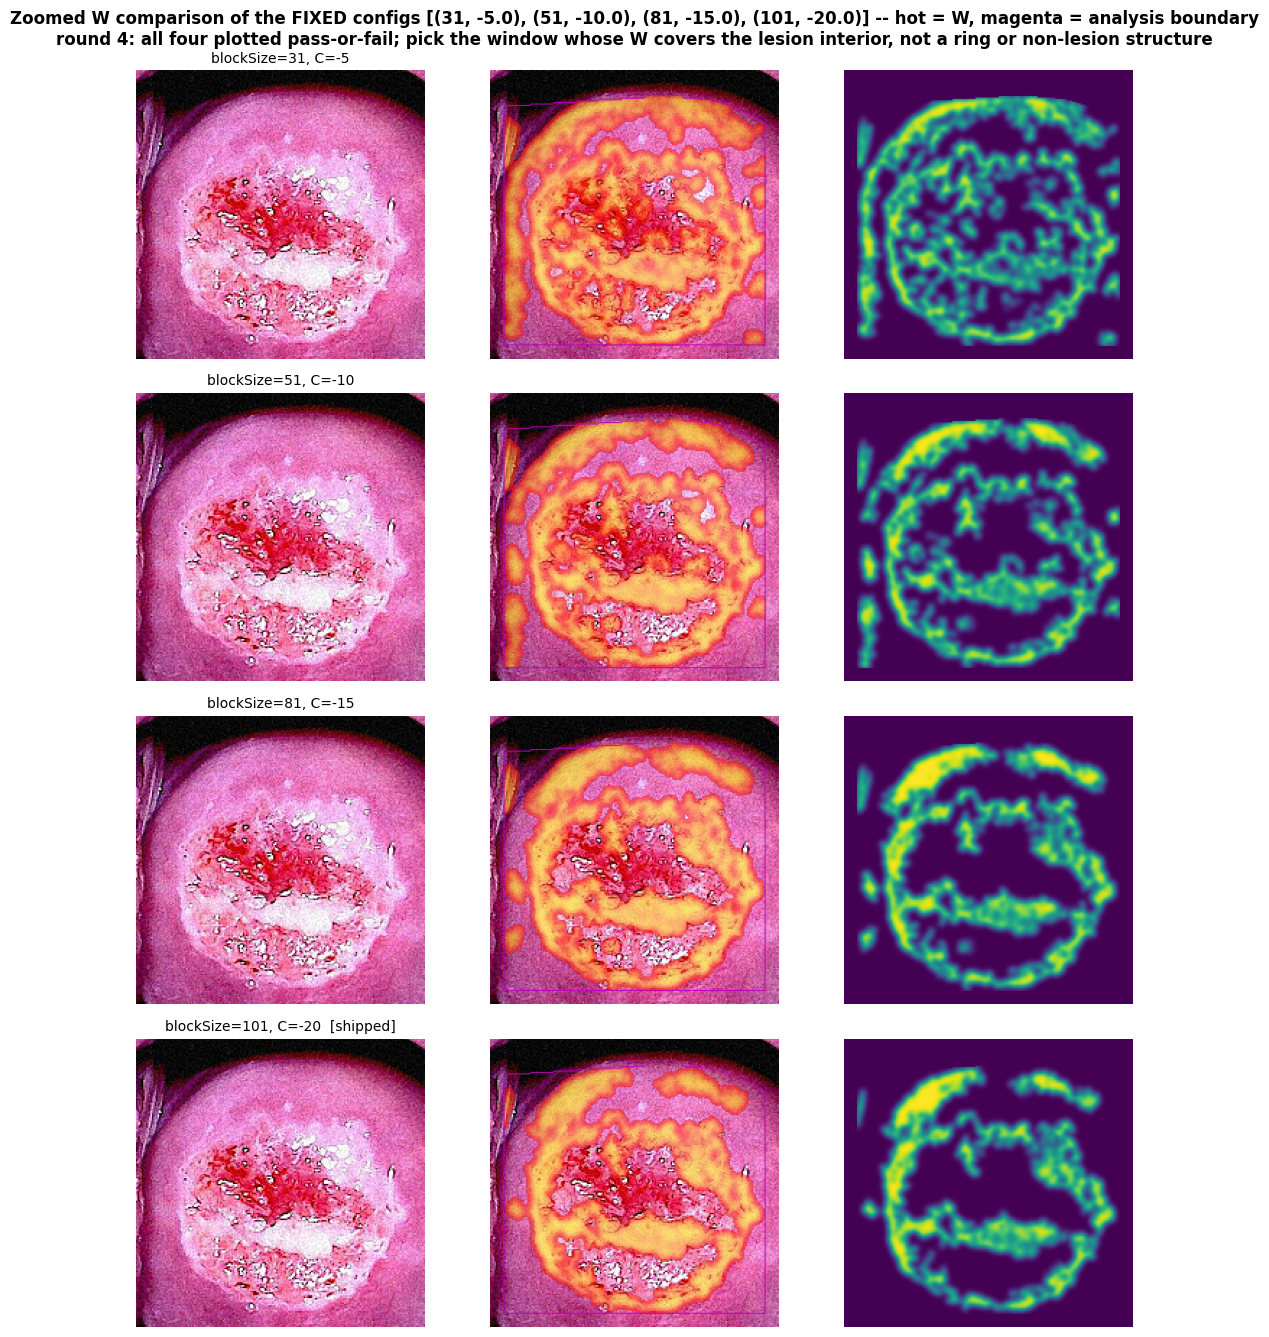

Saved results/fig_W_config_comparison.png

How to read this: 'thinness' >> 1 means the region is a thin RING (the
51 px-window failure mode); a high 'border-share' means W hugs the
analysis boundary. Round 6 verdict: RETIRE -- the config is FROZEN at (101, -20);
no window fixes the lesion-interior problem (W is a ring at every size).

Round-4 change: these four configs are ALWAYS plotted (pass or fail),
because the comparison itself is the point of this cell.


In [11]:
# ============================================================
# Step 4.1c -- ZOOMED W COMPARISON of the FIXED configs (round 4).
#   The four configs (31,-5), (51,-10), (81,-15), (101,-20) are ALWAYS
#   plotted, whether or not they pass -- the comparison is the point.
#   Rows = configs. Columns = zoomed original / zoomed W overlay /
#   full-frame W. The zoom window is the bounding box of the union of
#   the W >= 0.5 regions across the shown configs on the REPRESENTATIVE
#   frame (median coverage at the shipped config) -- data-driven, no
#   lesion mask needed.
#   Per config it also prints quantitative guidance: coverage, mean W,
#   THINNESS ratio (|R| / |erode(R,6)| -- rings/thin structures are
#   large), border-band share, in-region noise (abs, input-relative and
#   GM-relative), and -- when lesion masks exist -- the lesion overlap.
# ============================================================
_show = list(W_COMPARE_CONFIGS)   # FIXED: always these four
_shipped_pair = (int(AT_BLOCK_SIZE), float(AT_C))

# Representative frame: median coverage at the shipped config
_cov_img = []
for _i in range(n_images):
    _a = adaptive_threshold_preprocess(images[_i], return_artefacts=True,
                                       fov_mask=fov[_i],
                                       block_size=_shipped_pair[0], c=_shipped_pair[1])
    _cov_img.append(_a['region_coverage'])
_rep = int(np.argsort(_cov_img)[len(_cov_img) // 2])
print(f"Representative frame for the comparison: img {_rep} "
      f"(median coverage at the shipped config {_shipped_pair})")

_cfg_arts = {}
_union = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
for _cfg in _show:
    _a = adaptive_threshold_preprocess(images[_rep], return_artefacts=True,
                                       fov_mask=fov[_rep],
                                       block_size=_cfg[0], c=_cfg[1])
    _cfg_arts[_cfg] = _a
    _union |= (_a['soft_mask'] >= 0.5) & _a['analysis_region']

if _union.any():
    _ys, _xs = np.where(_union)
    _pad = 24
    _y0 = max(int(_ys.min()) - _pad, 0); _y1 = min(int(_ys.max()) + _pad, IMG_SIZE)
    _x0 = max(int(_xs.min()) - _pad, 0); _x1 = min(int(_xs.max()) + _pad, IMG_SIZE)
else:
    _y0, _y1, _x0, _x1 = 40, 160, 40, 160   # central fallback crop
print(f"Zoom window: rows {_y0}-{_y1}, cols {_x0}-{_x1} "
      "(bounding box of the union of the W>=0.5 regions, padded)")

fig_z, axes_z = plt.subplots(len(_show), 3, figsize=(11, 3.4 * len(_show)), squeeze=False)
print("\nPer-config quantitative guidance (representative frame):")
print(f"  {'cfg':>14} {'cov%':>5} {'meanW':>6} {'thin':>5} {'bdr%':>4} "
      f"{'nr_abs':>7} {'nr/in':>6} {'nr/gm':>6}  pass")
_have_lesion_z = bool(len(masks) > 0 and masks.any())
for _r, _cfg in enumerate(_show):
    _a = _cfg_arts[_cfg]
    _W = _a['soft_mask']
    _ana = _a['analysis_region']
    _R = (_W >= 0.5) & _ana
    _thin = float(_R.sum() / max(int(ndimage.binary_erosion(_R, iterations=6).sum()), 1))
    _band = _ana & ~ndimage.binary_erosion(_ana, iterations=6)
    _bshare = float((_R & _band).sum() / max(_R.sum(), 1))
    _gm_img = global_boost_preprocess(images[_rep],
                                      gain=AT_ENHANCE_GAIN * _a['mean_W'])
    _nrin = _noise_ratio_in_region(images[_rep], _a['img_processed'], _R)
    _nringm = _noise_ratio_in_region(images[_rep], _gm_img, _R)
    _nrin_input = _noise_ratio_in_region(images[_rep], images[_rep], _R)
    _rel_abs = (_nrin / _nrin_input) if (np.isfinite(_nrin) and np.isfinite(_nrin_input)
                                          and _nrin_input > 1e-9) else float('nan')
    _rel_gm = (_nrin / _nringm) if (np.isfinite(_nrin) and np.isfinite(_nringm)
                                     and _nringm > 1e-9) else float('nan')
    _passes = bool(np.isfinite(_a['region_coverage']) and
                   AT_COVERAGE_LO <= _a['region_coverage'] <= AT_COVERAGE_HI and
                   np.isfinite(_rel_abs) and _rel_abs <= AT_NOISE_INW_ABS_MAX)
    _les_txt = ""
    if _have_lesion_z and masks[_rep].any():
        _lm = masks[_rep] & fov[_rep]
        _les_in = float((_R & _lm).sum() / max(_lm.sum(), 1))
        _les_txt = f", lesion-cov {100*_les_in:.0f}%"
    # ---- panels ----
    ax = axes_z[_r, 0]
    ax.imshow(images[_rep][_y0:_y1, _x0:_x1])
    _tag = "  [shipped]" if _cfg == _shipped_pair else ""
    ax.set_title(f"blockSize={_cfg[0]}, C={_cfg[1]:g}{_tag}", fontsize=10)
    ax.axis('off')
    ax = axes_z[_r, 1]
    ax.imshow(images[_rep][_y0:_y1, _x0:_x1])
    _Wc = np.ma.masked_less(_W[_y0:_y1, _x0:_x1], 0.05)
    ax.imshow(_Wc, cmap='autumn', alpha=0.55, vmin=0, vmax=1)
    _cnts, _ = cv2.findContours(_ana[_y0:_y1, _x0:_x1].astype(np.uint8),
                                cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in _cnts:
        pts = cnt.squeeze(1)
        if pts.ndim == 1:
            continue
        ax.plot(pts[:, 0], pts[:, 1], '-m', linewidth=0.8, alpha=0.9)
    ax.axis('off')
    ax = axes_z[_r, 2]
    ax.imshow(_W, cmap='viridis', vmin=0, vmax=1)
    ax.axis('off')
    _pflag = "PASS" if _passes else "fail"
    print(f"  bs={_cfg[0]:>3}, C={_cfg[1]:>5g}: cov={100*_a['region_coverage']:5.1f}% "
          f"meanW={_a['mean_W']:.3f} thin={_thin:5.1f} bdr={100*_bshare:4.1f}% "
          f"nr_abs={_nrin if np.isfinite(_nrin) else float('nan'):.3f} "
          f"nr/in={_rel_abs if np.isfinite(_rel_abs) else float('nan'):.3f} "
          f"nr/gm={_rel_gm if np.isfinite(_rel_gm) else float('nan'):.3f}  {_pflag}{_les_txt}")
fig_z.suptitle("Zoomed W comparison of the FIXED configs "
               f"{W_COMPARE_CONFIGS} -- hot = W, magenta = analysis boundary\n"
               "round 4: all four plotted pass-or-fail; pick the window whose W covers "
               "the lesion interior, not a ring or non-lesion structure",
               fontsize=12, fontweight='bold')
plt.tight_layout()
fig_z.savefig(os.path.join(SAVE_DIR, "fig_W_config_comparison.png"), dpi=150)
plt.show()
print(f"Saved {SAVE_DIR}/fig_W_config_comparison.png")
print("\nHow to read this: 'thinness' >> 1 means the region is a thin RING (the")
print("51 px-window failure mode); a high 'border-share' means W hugs the")
print("analysis boundary. Round 6 verdict: RETIRE -- the config is FROZEN at (101, -20);")
print("no window fixes the lesion-interior problem (W is a ring at every size).")
print("\nRound-4 change: these four configs are ALWAYS plotted (pass or fail),")
print("because the comparison itself is the point of this cell.")


In [12]:
# ============================================================
# Cell 4.2 -- step4_validator + helper functions. Computes 11 metrics
#             inside the FOV only, per image.
#   * Vessel Dice polarity: Frangi runs on the GREEN channel with
#     black_ridges=True (vessels are DARKER than the surrounding
#     tissue; bright_ridges would detect specular structures).
#   * Vessel maps are CACHED per unique image (md5 of the bytes): the
#     same map is reused across m6, T8 and every technique.
# ============================================================

_VESSEL_MAP_CACHE = {}

def _vessel_map(img_rgb, use_cache=True):
    """Frangi vessel filter -> vessel probability map (0-1), GREEN channel,
    black_ridges=True (vessels are dark ridges). Cached per unique image:
    the same map is reused across m6, T8 and every technique instead of
    being recomputed."""
    key = _hashlib.md5(np.ascontiguousarray(img_rgb).tobytes()).hexdigest()
    if use_cache and key in _VESSEL_MAP_CACHE:
        return _VESSEL_MAP_CACHE[key]
    green = np.ascontiguousarray(np.asarray(img_rgb)[..., 1]).astype(np.float32)
    try:
        v = _frangi_fn(green, black_ridges=True)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection (green channel)
        gx = cv2.Sobel(green, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(green, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    v = v.astype(np.float32)
    if use_cache:
        _VESSEL_MAP_CACHE[key] = v
    return v

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the region, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    (Pixel-wise correlation is ~0.997-0.999 for every variant, so the
    top-k Dice has more resolution.)"""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

# Single source of truth: the specular detector lives in Part A.
_specular_mask = specular_mask

def _effective_luma_bits(img_rgb, fov_mask):
    """Effective luma bit depth of the OUTPUT: log2 of the number of
    unique luma (Y) levels inside the FOV. 8.0 for any natural 8-bit
    image -- informational only, EXCLUDED from the ranked tables."""
    f = np.asarray(fov_mask, dtype=bool)
    y = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YUV)[..., 0]
    n_levels = int(np.unique(y[f]).size) if f.any() else 0
    return float(np.log2(max(n_levels, 2)))

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                    up
      m2  SSIM                         up
      m3  CIE76 dE                     down
      m4  a* correlation               up
      m5  |mean a* shift|              down
      m6  Vessel Dice (top 10%)        up
      m7  Edge IoU                     up
      m8  Sharpness ratio (out/in)     neutral (0.9-1.1)
      m9  Noise ratio (out/in)         down
      m10 Saturation ratio (out/in)    down (<= 1 is good)
      m11 Luma bits (effective, out)   informational (not ranked)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels; green channel, dark ridges)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass, smooth pixels
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio with add-one smoothing:
    #     (|sp_p| + 1) / (|sp_o| + 1)
    # Measures NEW saturation introduced by the technique, NOT glare
    # removal. Ratio ~1 = unchanged; >1 = new saturated pixels added;
    # <= 1 is good (direction DOWN).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = (float(sp_p[f].sum()) + 1.0) / (float(sp_o[f].sum()) + 1.0)
    # m11: Luma bits (effective bit depth of the OUTPUT) -- informational
    m11 = _effective_luma_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",       "fidelity", "up"),
    ("m2",  "SSIM",            "fidelity", "up"),
    ("m3",  "CIE76 dE",        "colour",   "down"),
    ("m4",  "a* corr",         "colour",   "up"),
    ("m5",  "|a* shift|",      "colour",   "down"),
    ("m6",  "Vessel Dice",     "structure", "up"),
    ("m7",  "Edge IoU",        "structure", "up"),
    ("m8",  "Sharpness ratio", "quality",  "neutral"),
    ("m9",  "Noise ratio",     "quality",  "down"),
    ("m10", "Saturation ratio", "quality", "down"),
    ("m11", "Luma bits",       "cost",     "info"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
# Ranked metrics = everything except the informational m11 (Luma bits
# is 8.000 for every natural 8-bit image and carries no information).
RANKED_METRIC_KEYS = [mk for mk in METRIC_KEYS if METRIC_BETTER[mk] != "info"]
print("step4_validator ready: 11 metrics (m1..m11); "
      f"ranked tables use {len(RANKED_METRIC_KEYS)} (m11 kept as a footnote).")
print("Vessel maps: Frangi on the GREEN channel, black_ridges=True, "
      f"cached per unique image ({'Frangi OK' if _FRANGI_OK else 'Sobel fallback'}).")


step4_validator ready: 11 metrics (m1..m11); ranked tables use 10 (m11 kept as a footnote).
Vessel maps: Frangi on the GREEN channel, black_ridges=True, cached per unique image (Frangi OK).


In [13]:
# ============================================================
# Cell 4.2b -- Metric-set reconciliation.
#   The QI-SABP validation notes list 12 metrics; THIS notebook
#   implements 11. Until the missing one is identified, tables are NOT
#   guaranteed comparable across the 26 notebooks.
# ============================================================
print("Metric registry implemented in THIS notebook (11 metrics):")
for _mk in METRIC_KEYS:
    print(f"  {_mk:>4}  {METRIC_NAMES[_mk]:<18} group={METRIC_GROUPS[_mk]:<10} "
          f"better: {METRIC_BETTER[_mk]}")
print("\nNotes:")
print("  - m11 (Luma bits) is informational: 8.000 for every natural 8-bit image;")
print("    it is excluded from the ranked tables and kept as a footnote only.")
print("  - The QI-SABP notes say the validation uses 12 metrics; this notebook")
print("    implements 11. RECONCILIATION IS OPEN: check the notes and either")
print("    restore the missing metric here or correct the notes, so the tables")
print("    stay comparable across the 26 notebooks.")
print("  - Leading hypothesis: the missing 12th metric is the codec bit-budget")
print("    metric. A non-codec preprocessor produces no byte stream, so it would")
print("    not apply here. UNCONFIRMED -- confirm against YOUR notes (the")
print("    reconciliation cannot be closed from inside this notebook).")
print("  - Definitions: m1 10*log10(255^2/MSE) in FOV; m2 FOV-masked SSIM; m3 mean")
print("    CIE76 dE in FOV; m4 Pearson r of a*; m5 |mean a* shift|; m6 Dice of top")
print("    10% Frangi (green, dark ridges); m7 Canny edge IoU; m8 Laplacian-var")
print("    ratio; m9 MAD high-pass noise ratio; m10 add-one specular-count ratio.")


Metric registry implemented in THIS notebook (11 metrics):
    m1  PSNR (dB)          group=fidelity   better: up
    m2  SSIM               group=fidelity   better: up
    m3  CIE76 dE           group=colour     better: down
    m4  a* corr            group=colour     better: up
    m5  |a* shift|         group=colour     better: down
    m6  Vessel Dice        group=structure  better: up
    m7  Edge IoU           group=structure  better: up
    m8  Sharpness ratio    group=quality    better: neutral
    m9  Noise ratio        group=quality    better: down
   m10  Saturation ratio   group=quality    better: down
   m11  Luma bits          group=cost       better: info

Notes:
  - m11 (Luma bits) is informational: 8.000 for every natural 8-bit image;
    it is excluded from the ranked tables and kept as a footnote only.
  - The QI-SABP notes say the validation uses 12 metrics; this notebook
    implements 11. RECONCILIATION IS OPEN: check the notes and either
    restore the missing m

In [14]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Adaptive Thresholding.
#   * The precomputed FOV (Step 4.1) is PASSED to the pipeline, so the
#     cached processed images and the T5/T8 region tables cannot
#     disagree.
#   * AT artefacts (soft W, binary map, analysis region, coverage,
#     in-region noise) are CACHED here, so T5/T8 and the gain-matched
#     control reuse the exact region that produced the cached images.
#   * CSV deletion uses a FIXED list (no glob): a broad glob could wipe
#     other techniques' CSVs living in the same folder.
# ============================================================
import os as _os

_MANAGED_CSVS = [
    "results_Adaptive_Thresholding.csv",
    "results_Identity.csv",
    "results_SharpenOnly.csv",
    "results_GlobalBoost.csv",
    "results_GlobalBoostGM.csv",
    "results_RawResized.csv",
    "results_gainsweep.csv",
    "results_per_image_AT_vs_GM.csv",
    "results_T8_per_image.csv",
    "results_ablation.csv",
    "metrics_summary.csv",
]
for _name in _MANAGED_CSVS:
    if _os.path.exists(_name):
        _os.remove(_name)
        print(f"  Deleted stale {_name}")
print("(fixed deletion list -- other techniques' CSVs in this folder are untouched)")

TECHNIQUE = "Adaptive Thresholding"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB
artefacts_cache = {}   # (TECHNIQUE, image_idx) -> AT artefacts dict

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    art_i = adaptive_threshold_preprocess(orig, return_artefacts=True,
                                          fov_mask=fov_i)
    proc = art_i['img_processed']
    m = step4_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    artefacts_cache[(TECHNIQUE, i)] = art_i
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_at = pd.DataFrame(rows)
df_at.to_csv("results_Adaptive_Thresholding.csv", index=False)
print(f"Wrote results_Adaptive_Thresholding.csv ({len(df_at)} rows = variants of AAM1)")
print(f"  Mean PSNR = {df_at['m1'].mean():.2f} dB | Mean SSIM = {df_at['m2'].mean():.4f} "
      f"| Mean dE76 = {df_at['m3'].mean():.4f}")

# ---- Coverage / noise REPORT (round 5: REPORTED, not binding -- verdict = RETIRE) ----
_covs = [artefacts_cache[(TECHNIQUE, i)]['region_coverage'] for i in range(n_images)]
_mean_cov = float(np.mean(_covs))
_noise_ratios = [_noise_ratio_local(images[i], processed_cache[(TECHNIQUE, i)], fov[i])
                 for i in range(n_images)]
_mean_nr = float(np.nanmean(_noise_ratios))
_nrin_abs = [artefacts_cache[(TECHNIQUE, i)]['nr_in_abs'] for i in range(n_images)]
_mean_nrin = float(np.nanmean(_nrin_abs))
_nrin_input = []
for i in range(n_images):
    _rin = (artefacts_cache[(TECHNIQUE, i)]['soft_mask'] >= 0.5) & \
            artefacts_cache[(TECHNIQUE, i)]['analysis_region']
    _nrin_input.append(_noise_ratio_in_region(images[i], images[i], _rin))
_mean_nrin_input = float(np.nanmean(_nrin_input))
_mean_nrin_abs_rel = (_mean_nrin / _mean_nrin_input
                      if _mean_nrin_input > 1e-9 else float('nan'))
_cov_W_of_FOV = []
for i in range(n_images):
    _rin = (artefacts_cache[(TECHNIQUE, i)]['soft_mask'] >= 0.5) & \
            artefacts_cache[(TECHNIQUE, i)]['analysis_region']
    _cov_W_of_FOV.append(float(_rin.sum() / max(fov[i].sum(), 1)))
_mean_cov_W_of_FOV = float(np.mean(_cov_W_of_FOV))
print(f"  Mean AT region coverage (of the ANALYSIS region) = "
      f"{100*_mean_cov:.1f}%  [reference range {AT_COVERAGE_LO:.0%}-{AT_COVERAGE_HI:.0%}]")
print(f"  Mean smooth-region noise ratio (m9) = {_mean_nr:.3f}  "
      f"[reference <= {AT_NOISE_RATIO_MAX}]")
print(f"  Mean noise INSIDE W>=0.5 (abs) = {_mean_nrin:.3f}, INPUT = {_mean_nrin_input:.3f}  "
      f"-> ratio = {_mean_nrin_abs_rel:.3f}  [ABSOLUTE, reported; cap {AT_NOISE_INW_ABS_MAX}]")
print(f"  COVERAGE UNIFICATION (the three numbers, all reported):")
print(f"    coverage (of ANALYSIS region) = {100*_mean_cov:.1f}%   <- grid 'coverage' column")
print(f"    cov_W_of_FOV (|W>=0.5| / |FOV|) = {100*_mean_cov_W_of_FOV:.1f}%   <- grid 'cov_W_of_FOV' column")
print(f"    nr_in_abs_rel = {_mean_nrin_abs_rel:.3f}   <- grid 'nr_in_abs_rel' column")
print(f"  Round-5 verdict: RETIRE. These numbers are REPORTED, not pass/fail --")
print(f"  the technique is retired regardless (see header). No OUT OF RANGE verdict.")
if SYNTHETIC_MODE:
    print("  NOTE (synthetic fallback): re-read on the REAL dataset.")
    print("  the criteria check is only meaningful on the REAL dataset.")


  Deleted stale results_Adaptive_Thresholding.csv
  Deleted stale results_Identity.csv
  Deleted stale results_SharpenOnly.csv
  Deleted stale results_GlobalBoost.csv
  Deleted stale results_GlobalBoostGM.csv
  Deleted stale results_RawResized.csv
  Deleted stale results_gainsweep.csv
  Deleted stale results_per_image_AT_vs_GM.csv
  Deleted stale results_T8_per_image.csv
  Deleted stale results_ablation.csv
  Deleted stale metrics_summary.csv
(fixed deletion list -- other techniques' CSVs in this folder are untouched)
  processed 16/16 images...
Wrote results_Adaptive_Thresholding.csv (16 rows = variants of AAM1)
  Mean PSNR = 47.19 dB | Mean SSIM = 0.9982 | Mean dE76 = 0.3324
  Mean AT region coverage (of the ANALYSIS region) = 16.5%  [reference range 15%-35%]
  Mean smooth-region noise ratio (m9) = 1.044  [reference <= 1.1]
  Mean noise INSIDE W>=0.5 (abs) = 1.217, INPUT = 1.000  -> ratio = 1.217  [ABSOLUTE, reported; cap 1.2]
  COVERAGE UNIFICATION (the three numbers, all reported):

In [15]:
# ============================================================
# Step 4.4 -- Reference row: Identity (ideal values, not ranked).
#   Its PSNR is displayed as infinity in the tables (a finite 148 dB
#   number carried no meaning), and it is excluded from the T8 region
#   split (identical by construction) and from T7 (zero variance makes
#   every CI 'exclude 0' by construction).
# ============================================================

for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()

rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows = variants of AAM1)")
print("  Identity is a reference row: dE=0, Dice=1.0, IoU=1.0; PSNR is")
print("  displayed as infinity in the tables (identical images).")


Wrote results_Identity.csv (16 rows = variants of AAM1)
  Identity is a reference row: dE=0, Dice=1.0, IoU=1.0; PSNR is
  displayed as infinity in the tables (identical images).


In [16]:
# ============================================================
# Step 4.4b -- Baselines, validated with the SAME 11 metrics and cached
#              for the region-split tables:
#   * SharpenOnly : input (already sharpened by Step 1) -> SECOND unsharp
#                   mask, no thresholding. THE key control: if AT only
#                   ever matches this, adaptive thresholding contributes
#                   nothing beyond extra sharpening.
#   * GlobalBoost : the same detail-band boost as AT with W = 1 at FULL
#                   AT_ENHANCE_GAIN (no region selection).
#   * GlobalBoostGM: GAIN-MATCHED global boost -- the same enhancement
#                   with gain = AT_ENHANCE_GAIN x mean(W), i.e. the same
#                   total boost strength as AT. This is the comparison
#                   that isolates REGION SELECTION; every fidelity-vs-
#                   input metric rewards doing less, so AT 'wins' T1
#                   partly by boosting less.
#   * RawResized  : resize-only REFERENCE row (kept OUT of the ranked
#                   tables) -- scored against the SHARPENED input, its
#                   fidelity numbers measure the Step-1 sharpening
#                   itself (an 'un-sharpening' distance), not quality.
#   After the GM run: the GM-relative IN-REGION noise check (the third
#   acceptance criterion) -- AT's noise inside W>=0.5 vs the same ratio
#   for the uniform boost of the same total strength.
# ============================================================

def _run_baseline(name, proc_fn, description):
    rows_b = []
    for i in range(n_images):
        proc = proc_fn(i)
        m = step4_validator(images[i], proc, fov[i])
        m["technique"] = name
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows_b.append(m)
        processed_cache[(name, i)] = proc.copy()
    df_b = pd.DataFrame(rows_b)
    df_b.to_csv(f"results_{name}.csv", index=False)
    print(f"Wrote results_{name}.csv ({len(df_b)} rows = variants of AAM1) -- {description}")
    print(f"  Mean PSNR = {df_b['m1'].mean():.2f} dB | Mean SSIM = {df_b['m2'].mean():.4f} "
          f"| Mean dE76 = {df_b['m3'].mean():.4f} | Sharpness ratio = {df_b['m8'].mean():.3f} "
          f"| Noise ratio = {df_b['m9'].mean():.3f}")
    return df_b

df_sharpen_only = _run_baseline(
    "SharpenOnly",
    lambda i: sharpen(images[i]),
    "second unsharp mask on the (already sharpened) input, no thresholding")
df_global_boost = _run_baseline(
    "GlobalBoost",
    lambda i: global_boost_preprocess(images[i]),
    "same detail-band boost as AT with W=1 at FULL gain (no region selection)")

# Gain-matched control: gain = AT_ENHANCE_GAIN x mean W over the batch
# (AT artefacts were cached in Step 4.3).
_meanW_batch = float(np.mean([artefacts_cache[(TECHNIQUE, i)]['mean_W']
                              for i in range(n_images)]))
gm_gain = AT_ENHANCE_GAIN * _meanW_batch
print(f"\nGain-matched control: mean W over the batch = {_meanW_batch:.3f} -> "
      f"GlobalBoostGM gain = {AT_ENHANCE_GAIN} x {_meanW_batch:.3f} = {gm_gain:.3f} "
      f"(AT effective gain = gain x meanW)")
df_global_boost_gm = _run_baseline(
    "GlobalBoostGM",
    lambda i: global_boost_preprocess(images[i], gain=gm_gain),
    f"gain-matched global boost (gain = {AT_ENHANCE_GAIN} x meanW = {gm_gain:.3f})")
df_raw_resized = _run_baseline(
    "RawResized",
    lambda i: images_raw[i].copy(),
    "resize-only REFERENCE (separates the Step-1 sharpen effect; NOT ranked)")
print("\nAll four baselines (SharpenOnly, GlobalBoost, GlobalBoostGM, RawResized)")
print("are cached in processed_cache, so T8 gives them the same region-split")
print("treatment as AT. RawResized is kept out of the ranked tables (reference).")

# ---- GM-relative IN-REGION noise check (the third acceptance criterion) ----
_nrin_at_l, _nrin_gm_l = [], []
for i in range(n_images):
    _art = artefacts_cache[(TECHNIQUE, i)]
    _rin = (_art['soft_mask'] >= 0.5) & _art['analysis_region']
    _nrin_at_l.append(_noise_ratio_in_region(images[i], processed_cache[(TECHNIQUE, i)], _rin))
    _nrin_gm_l.append(_noise_ratio_in_region(images[i], processed_cache[("GlobalBoostGM", i)], _rin))
_nrin_at_m = float(np.nanmean(_nrin_at_l))
_nrin_gm_m = float(np.nanmean(_nrin_gm_l))
_nrin_rel = _nrin_at_m / _nrin_gm_m if (_nrin_gm_m and np.isfinite(_nrin_gm_m)
                                        and _nrin_gm_m > 1e-9) else float('nan')
print(f"\nIN-REGION noise check (inside W>=0.5, MAD high-pass estimator):")
print(f"  AT (abs)                 = {_nrin_at_m:.3f}")
print(f"  GlobalBoostGM (abs)      = {_nrin_gm_m:.3f}   (same total boost, uniform)")
print(f"  AT / GM ratio            = {_nrin_rel:.3f}   "
      f"[cap {AT_NOISE_INW_MAX}; reported, not binding -- verdict = RETIRE]")
print("  The absolute in-region ratio rises with total gain by construction;")
print("  the GM-relative ratio asks whether REGION SELECTION adds noise beyond")
print("  what the same total boost adds uniformly. This is the check the m9")
print("  smooth-region estimator could not provide (W sits on edges).")


Wrote results_SharpenOnly.csv (16 rows = variants of AAM1) -- second unsharp mask on the (already sharpened) input, no thresholding
  Mean PSNR = 25.59 dB | Mean SSIM = 0.9286 | Mean dE76 = 5.1789 | Sharpness ratio = 2.214 | Noise ratio = 1.567
Wrote results_GlobalBoost.csv (16 rows = variants of AAM1) -- same detail-band boost as AT with W=1 at FULL gain (no region selection)
  Mean PSNR = 30.96 dB | Mean SSIM = 0.9771 | Mean dE76 = 2.7626 | Sharpness ratio = 1.534 | Noise ratio = 1.295

Gain-matched control: mean W over the batch = 0.163 -> GlobalBoostGM gain = 0.35 x 0.163 = 0.057 (AT effective gain = gain x meanW)
Wrote results_GlobalBoostGM.csv (16 rows = variants of AAM1) -- gain-matched global boost (gain = 0.35 x meanW = 0.057)
  Mean PSNR = 45.21 dB | Mean SSIM = 0.9989 | Mean dE76 = 0.5144 | Sharpness ratio = 1.087 | Noise ratio = 1.074
Wrote results_RawResized.csv (16 rows = variants of AAM1) -- resize-only REFERENCE (separates the Step-1 sharpen effect; NOT ranked)
  Mean P

In [17]:
# ============================================================
# Step 4.4c -- GAIN SWEEP: does REGION SELECTION beat a uniform boost
#              of the same effective strength, at ANY gain?
#   For each g in GAIN_SWEEP_GAINS {0.35, 0.6, 1.0}:
#     * AT(g) with the SHIPPED config -> effective gain g_eff = g x mean W_i;
#     * GlobalBoostGM(g_eff): the SAME enhancement applied uniformly at
#       exactly the same total strength;
#     * paired per-image differences (AT - control) for the key metrics
#       + bootstrap CI over the variants.
#   At the shipped 0.35 x 0.193 = 0.057 effective gain the comparison could
#   barely answer anything -- the technique is almost a no-op (PSNR ~47 dB,
#   SSIM ~0.998). If AT never beats the matched control on >=2
#   non-confounded metrics (and shows no Vessel Dice loss), the honest
#   conclusion is that region selection adds nothing measurable on this
#   frame set: retire or re-purpose, do not re-tune. Saved to
#   results_gainsweep.csv.
#
#   DECISION RULE (round 5):
#     * "AT wins" at a gain requires:
#       (a) >=2 of the NON-CONFOUNDED metrics {m3 dE, m6 Vessel Dice,
#           m9 Noise ratio} favour AT with a CI excluding 0 AND a
#           meaningful effect size; AND
#       (b) NO loss on Vessel Dice (m6) -- vessel structure is the
#           primary anatomy-preserving check.
#     * Edge IoU (m7) alone NEVER triggers "AT wins": a Canny-edge IoU
#       gain can come from noise suppression, not region selection.
#     * m8 (Sharpness) is neutral (gain-confounded) -- reported, not judged.
# ============================================================

def _boot_ci_mean(vals, n_boot=2000, seed=42):
    """Mean + bootstrap CI over the given per-image values."""
    v = np.asarray([x for x in vals if np.isfinite(x)], dtype=float)
    if len(v) < 2:
        m = float(v.mean()) if len(v) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(v), size=(n_boot, len(v)))
    boots = v[idx].mean(axis=1)
    return (float(v.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Metric definitions. "confounded" metrics are gain-related and cannot
# by themselves justify region selection.
_sweep_metric_defs = [
    # (key, name, direction, threshold, confounded?)
    ("m3", "dE76",          "down",    0.5,  False),
    ("m6", "Vessel Dice",   "up",      0.01, False),
    ("m7", "Edge IoU",      "up",      0.02, True),   # confounded (noise suppression)
    ("m9", "Noise ratio",   "down",    0.05, False),
    ("m8", "Sharpness",     "neutral", 0.10, True),   # confounded (gain)
]
# The non-confounded metrics that can trigger "AT wins":
_NONCONFOUNDED = {"m3", "m6", "m9"}

_sweep_rows = []
_sweep_summary = {}
print(f"Gain sweep on {n_images} variants (N=1, AAM1) with the SHIPPED config "
      f"(blockSize={AT_BLOCK_SIZE}, C={AT_C:g}); control = uniform boost at the "
      "same effective gain per image.")
print(f"DECISION RULE (round 5): 'AT wins' at a gain requires >=2 of "
      f"{sorted(_NONCONFOUNDED)} favouring AT (CI excludes 0 + effect size) AND no "
      "Vessel Dice loss. Edge IoU alone NEVER triggers a win.")
for _g in GAIN_SWEEP_GAINS:
    _diffs = {mk: [] for mk, *_ in _sweep_metric_defs}
    _geffs, _nrin_at, _nrin_gm = [], [], []
    for i in range(n_images):
        art_i = adaptive_threshold_preprocess(images[i], return_artefacts=True,
                                              fov_mask=fov[i], gain=_g)
        proc_at = art_i['img_processed']
        _geff = _g * art_i['mean_W']
        proc_gm = global_boost_preprocess(images[i], gain=_geff)
        m_at = step4_validator(images[i], proc_at, fov[i])
        m_gm = step4_validator(images[i], proc_gm, fov[i])
        for mk in _diffs:
            _diffs[mk].append(m_at[mk] - m_gm[mk])
        _rin = (art_i['soft_mask'] >= 0.5) & art_i['analysis_region']
        _nrin_at.append(_noise_ratio_in_region(images[i], proc_at, _rin))
        _nrin_gm.append(_noise_ratio_in_region(images[i], proc_gm, _rin))
        _geffs.append(_geff)
        _sweep_rows.append({
            "gain": _g, "image_id": image_id[i],
            "file": os.path.basename(paths_raw[i])[:32],
            "effective_gain": _geff,
            "mean_W": art_i['mean_W'],
            **{f"diff_{mk}": _diffs[mk][-1] for mk in _diffs},
            "nr_in_AT": _nrin_at[-1], "nr_in_GM": _nrin_gm[-1],
        })
    _summary = {}
    print(f"\n--- gain = {_g:g}  (effective gain = {_g:g} x meanW = "
          f"{float(np.mean(_geffs)):.3f}) ---")
    for mk, name, direction, thr, _conf in _sweep_metric_defs:
        md, lo, hi = _boot_ci_mean(_diffs[mk])
        excl = bool(np.isfinite(lo) and np.isfinite(hi) and (lo > 0 or hi < 0))
        if direction == "down":
            favours = "AT" if (np.isfinite(hi) and hi < 0 and abs(md) >= thr) else (
                "GM" if (np.isfinite(lo) and lo > 0 and abs(md) >= thr) else "-")
        elif direction == "up":
            favours = "AT" if (np.isfinite(lo) and lo > 0 and abs(md) >= thr) else (
                "GM" if (np.isfinite(hi) and hi < 0 and abs(md) >= thr) else "-")
        else:
            favours = "-"
        _summary[mk] = {"mean": md, "lo": lo, "hi": hi, "excl": excl,
                        "favours": favours, "confounded": _conf}
        _tag = " [confounded]" if _conf else ""
        print(f"  {name:<12} AT-GM = {md:+.4f} [{lo:+.4f}, {hi:+.4f}] "
              f"CI!=0: {'yes' if excl else 'no ':<3} favours: {favours}{_tag}")
    _nrin_rel = (float(np.nanmean(_nrin_at)) / float(np.nanmean(_nrin_gm))
                 if np.nanmean(_nrin_gm) > 1e-9 else float('nan'))
    print(f"  in-region noise AT/GM = {_nrin_rel:.3f} (legacy GM-relative, reported)")
    _sweep_summary[_g] = _summary

pd.DataFrame(_sweep_rows).to_csv("results_gainsweep.csv", index=False)
print(f"\nWrote results_gainsweep.csv ({len(_sweep_rows)} rows = gains x variants)")
print("\nNOTE on the 'favours' column: AT's dE is significantly LOWER than the matched")
print("control at every gain (a fidelity-vs-input win), but the sweep labels it '-')")
print("because dE measures distance FROM the input and rewards changing least -- AT's")
print("effective gain (0.057) is far below GlobalBoostGM's, so AT changes less by")
print("construction. A dE 'win' here is a gain difference, NOT a region-selection effect.")
print("The decision rule (>=2 non-confounded metrics, no Dice loss) ignores dE for this")
print("reason: it is confounded by the strength gap even at matched gain, because the")
print("matched gain is per-image meanW, not per-region.")

# ---- Decision block (round 5 rule) ----
print("\n" + "=" * 80)
print("DECISION (round 5 rule: what is AT for?)")
print("=" * 80)
_any_win = False
for _g in GAIN_SWEEP_GAINS:
    _s = _sweep_summary[_g]
    # (a) count non-confounded metrics favouring AT with CI excluding 0
    _nc_at = [mk for mk in _NONCONFOUNDED
              if _s[mk]["favours"] == "AT" and _s[mk]["excl"]]
    # (b) Vessel Dice loss?
    _dice_loss = (_s["m6"]["favours"] == "GM" and _s["m6"]["excl"])
    _wins = (len(_nc_at) >= 2) and (not _dice_loss)
    if _wins:
        _any_win = True
        print(f"\n  gain {_g:g}: AT WINS on {len(_nc_at)} non-confounded metrics "
              f"({[m for m in _nc_at]}), no Vessel Dice loss.")
        print(f"    effective gain = {_g:g} x meanW; pick the LOWEST winning gain.")
    else:
        _reason = []
        if len(_nc_at) < 2:
            _reason.append(f"only {len(_nc_at)} non-confounded metric(s) favour AT "
                            f"(need >=2: {_nc_at})")
        if _dice_loss:
            _reason.append("Vessel Dice LOSS (m6 favours GM with CI!=0)")
        print(f"\n  gain {_g:g}: no win -- " + "; ".join(_reason) + ".")

if _any_win:
    print("\n  => AT has a measurable regional effect at the gain(s) above; pick the")
    print("     lowest such gain, state the effect size, and re-check the noise")
    print("     criteria (absolute in-region) at that gain.")
else:
    print("\n  Across gains " + ", ".join(f"{g:g}" for g in GAIN_SWEEP_GAINS) +
          " AT NEVER beat the uniform boost on >=2 non-confounded metrics with no")
    print("  Vessel Dice loss. Region selection adds nothing measurable on this")
    print("  frame set (N=1): either retire the technique from the suite, or")
    print("  re-purpose it -- the W map itself as a lesion-candidate overlay --")
    print("  and stop tuning the enhancement.")
    print("\n  NOTE: Edge IoU (m7) is reported but NEVER triggers a win on its own,")
    print("  because a Canny-edge IoU gain can come from noise suppression, not")
    print("  region selection. The old rule (any single metric) was too permissive.")


Gain sweep on 16 variants (N=1, AAM1) with the SHIPPED config (blockSize=101, C=-20); control = uniform boost at the same effective gain per image.
DECISION RULE (round 5): 'AT wins' at a gain requires >=2 of ['m3', 'm6', 'm9'] favouring AT (CI excludes 0 + effect size) AND no Vessel Dice loss. Edge IoU alone NEVER triggers a win.

--- gain = 0.35  (effective gain = 0.35 x meanW = 0.057) ---
  dE76         AT-GM = -0.2089 [-0.2366, -0.1832] CI!=0: yes favours: -
  Vessel Dice  AT-GM = -0.0094 [-0.0151, -0.0042] CI!=0: yes favours: -
  Edge IoU     AT-GM = +0.0273 [+0.0197, +0.0345] CI!=0: yes favours: AT [confounded]
  Noise ratio  AT-GM = -0.0361 [-0.0531, -0.0188] CI!=0: yes favours: -
  Sharpness    AT-GM = -0.0401 [-0.0458, -0.0351] CI!=0: yes favours: - [confounded]
  in-region noise AT/GM = 1.130 (legacy GM-relative, reported)

--- gain = 0.6  (effective gain = 0.6 x meanW = 0.098) ---
  dE76         AT-GM = -0.3135 [-0.3547, -0.2791] CI!=0: yes favours: -
  Vessel Dice  AT-GM = 

In [18]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs. Assert
#             each technique has the right rows and the same cluster
#             ids. Assert no NaNs (or list them).
#             Uses a FIXED list of CSV names (not glob) so stale files
#             from earlier runs cannot leak into the tables.
# ============================================================

_csv_names = [
    "results_Adaptive_Thresholding.csv",
    "results_Identity.csv",
    "results_SharpenOnly.csv",
    "results_GlobalBoost.csv",
    "results_GlobalBoostGM.csv",
    "results_RawResized.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques "
      f"(unit = {n_images} variants of AAM1 [N=1])")

# Hard assert: no NaN in any metric column.
_all_numeric_cols = [c for c in METRIC_KEYS if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, (
    f"NaN values found: {_nan_cols}. Check the validator outputs.")
print("No NaN values in any metric column.")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 6 CSV files (fixed list, not glob)
  results_Adaptive_Thresholding.csv: 16 rows, technique = Adaptive Thresholding
  results_Identity.csv: 16 rows, technique = Identity
  results_SharpenOnly.csv: 16 rows, technique = SharpenOnly
  results_GlobalBoost.csv: 16 rows, technique = GlobalBoost
  results_GlobalBoostGM.csv: 16 rows, technique = GlobalBoostGM
  results_RawResized.csv: 16 rows, technique = RawResized
Merged: 96 rows, 6 techniques (unit = 16 variants of AAM1 [N=1])
No NaN values in any metric column.
Techniques: ['Adaptive Thresholding', 'GlobalBoost', 'GlobalBoostGM', 'Identity', 'RawResized', 'SharpenOnly']


In [19]:
# ============================================================
# Cell 4.6 -- Aggregation: the mean is the PLAIN MEAN over the
#             variants of AAM1 (no cluster pre-averaging -- the unit of
#             analysis is N=1). The 95% interval comes from a
#             BOOTSTRAP OVER VARIANTS ({n_images} resampled, 2000
#             draws, fixed seed). VARIANT-SPREAD, not a population CI.
#             The old cluster-averaged pipeline is gone: with 8
#             byte-identical copies per image the clusters mostly
#             measured duplication, not diversity.
# ============================================================

def _unique_mean_and_ci(df, metric_key, n_boot=2000, seed=42):
    """Mean over variants + bootstrap interval resampling variants.
    VARIANT-SPREAD, NOT a population CI."""
    vals = pd.to_numeric(df[metric_key], errors="coerce").dropna().values.astype(float)
    if len(vals) < 2:
        m = float(vals.mean()) if len(vals) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(vals), size=(n_boot, len(vals)))
    boots = vals[idx].mean(axis=1)
    return (float(vals.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the variant mean and interval for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _unique_mean_and_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (variant mean + 95% variant-spread interval).")
print(f"  N=1: {n_images} augmented variants of AAM1 resampled (2000 draws), "
      "VARIANT-SPREAD interval, NOT a population CI.")
print("  Provenance: " + provenance_summary)


Aggregation done (variant mean + 95% variant-spread interval).
  N=1: 16 augmented variants of AAM1 resampled (2000 draws), VARIANT-SPREAD interval, NOT a population CI.
  Provenance: N=1: 16 augmentation variants of ONE source image (AAM1). All stems start with AAM1_ and carry flip/noise/rotation markers.


In [20]:
# ============================================================
# Step 4.7 -- Statistics: Adaptive Thresholding vs the BASELINES, per
#             key metric. PAIRED DIFFERENCE PER UNIQUE IMAGE + bootstrap
#             CI over the md5-unique images. Descriptive, no significance
#             claim.
#
#             * AT vs GlobalBoostGM is THE comparison: gain-matched, so
#               its differences read as REGION-SELECTION effects. It
#               carries the "meaningful" flag.
#             * AT vs SharpenOnly / GlobalBoost rows are GAIN-CONFOUNDED
#               (the review showed the earlier gaps were gain
#               differences): they are reported WITHOUT the meaningful
#               flag, reference only.
#             * Identity is NOT compared: zero variance would make every
#               CI 'exclude 0' by construction.
#             Per-image paired differences are stored for the T7 table.
# ============================================================

def _paired_image_diff_ci(diff_series, n_boot=2000, seed=42):
    """Bootstrap CI over paired per-image differences."""
    diff = np.asarray(diff_series, dtype=float)
    diff = diff[np.isfinite(diff)]
    if len(diff) < 2:
        return float(diff.mean()) if len(diff) else float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    boots = diff[idx].mean(axis=1)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison. PSNR/SSIM/luma-bits stay out
# (meaningless for these pairs: near-identical bit depth / duplicated
# information). m8/m10 ARE included: sharpness and saturation are what
# the strength gap actually moves.
key_metrics = ["m3", "m5", "m6", "m7", "m8", "m9", "m10"]

_comparison_targets = ["GlobalBoostGM", "SharpenOnly", "GlobalBoost"]
_GAIN_MATCHED_TARGETS = {"GlobalBoostGM"}   # the real comparison; flag lives here

at_df = merged[merged["technique"] == TECHNIQUE]
stat_rows = []
per_image_diff_frames = {}
for _tgt in _comparison_targets:
    _tgt_df = merged[merged["technique"] == _tgt]
    if len(_tgt_df) == 0:
        print(f"[warn] baseline {_tgt} missing from merged -- skipped")
        continue
    _t = at_df.set_index("image_id")
    _r = _tgt_df.set_index("image_id")
    _common = _t.index.intersection(_r.index)
    _diff_df = pd.DataFrame(
        {mk: _t.loc[_common, mk].values - _r.loc[_common, mk].values
         for mk in key_metrics},
        index=_common)
    _diff_df.insert(0, "file", [os.path.basename(paths_raw[i])[:32]
                                for i in range(n_images)
                                if image_id[i] in set(_common)])
    per_image_diff_frames[_tgt] = _diff_df
    for mk in key_metrics:
        md, lo, hi, ex = _paired_image_diff_ci(_diff_df[mk].values)
        # Variant count: how many of the n_images variants have AT BETTER than
        # the control on this metric (direction-aware). Replaces the "meaningful"
        # flag in the N=1 tables (round 5): with N=1 the variant count is the
        # honest summary, not a CI-excludes-0 flag.
        _diff_vals = _diff_df[mk].values
        _n_total = len(_diff_vals)
        if mk in ("m3", "m5", "m9", "m10"):  # DOWN-good: AT better when diff < 0
            _n_at_better = int(np.sum(_diff_vals < 0))
        else:  # UP-good or neutral: AT better when diff > 0
            _n_at_better = int(np.sum(_diff_vals > 0))
        stat_rows.append({
            "metric": METRIC_NAMES[mk],
            "comparison": f"{TECHNIQUE} vs {_tgt}",
            "gain_matched": "yes" if _tgt in _GAIN_MATCHED_TARGETS else "no",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
            "n_at_better": _n_at_better,
            "n_total": _n_total,
        })
stat_df = pd.DataFrame(stat_rows)
print("Statistics done: AT vs GlobalBoostGM (gain-matched, THE comparison),")
print("plus the gain-confounded SharpenOnly / GlobalBoost rows for reference.")
print("  Paired per variant; bootstrap interval resamples the variants of AAM1 (N=1).")
print("  Variant counts (n_at_better / n_total) replace the 'meaningful' flag in T7")
print("  (round 5): with N=1 the count is the honest summary, not a CI-excludes-0 flag.")
print("  (NOT vs Identity: Identity has zero variance, so every CI would")
print("   'exclude 0' by construction.)")
print("  Descriptive, no significance claim; variant-spread, not population.")


Statistics done: AT vs GlobalBoostGM (gain-matched, THE comparison),
plus the gain-confounded SharpenOnly / GlobalBoost rows for reference.
  Paired per variant; bootstrap interval resamples the variants of AAM1 (N=1).
  Variant counts (n_at_better / n_total) replace the 'meaningful' flag in T7
  (round 5): with N=1 the count is the honest summary, not a CI-excludes-0 flag.
  (NOT vs Identity: Identity has zero variance, so every CI would
   'exclude 0' by construction.)
  Descriptive, no significance claim; variant-spread, not population.


In [21]:
# ============================================================
# Print tables T1, T5, T7, T8, T6.
#   * Unit of analysis EVERYWHERE = N=1 (variants of AAM1); means are
#     plain variant means and intervals are variant-spread bootstraps.
#   * T1: m11 footnote only; Identity PSNR shown as infinity; RawResized
#     REMOVED from the ranked table (reference only); explicit note that
#     fidelity-vs-input metrics cannot rank enhancement techniques.
#   * T5: PER-VARIANT region split (one row per variant -- the CIs
#     rest on very few images, so the raw values are shown, not hidden
#     behind cluster averages).
#   * T7: two blocks -- AT vs GlobalBoostGM (gain-matched, carries the
#     meaningful flag) and the gain-confounded SharpenOnly/GlobalBoost
#     rows WITHOUT the flag; then the PER-VARIANT paired
#     differences vs GlobalBoostGM (16 rows).
#   * T8: region split per technique (means over uniques; the per-image
#     table is saved to results_T8_per_image.csv); Identity skipped.
#   * T6: caveats -- unit of analysis, provenance, Step-1 SUITE-LEVEL
#     decision, W-polarity, window/ring behaviour, in-region noise,
#     gain-sweep decision, no "chosen by these criteria" claim.
# ============================================================

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

_RAWREF_NOTE = ("RawResized is a REFERENCE row, NOT ranked: it is scored against the "
                "SHARPENED input, so its fidelity numbers measure the Step-1 sharpening "
                "itself (an 'un-sharpening' distance), not technique quality. "
                "Full row: results_RawResized.csv.")
_RANKED_TECHS = [t for t in techniques if t != "RawResized"]

_have_lesion = bool(masks.any())
if _have_lesion:
    _lesion_count = int(masks.any((1, 2)).sum())

# ---- AT region masks per image, from the CACHED artefacts (no recompute) ----
_at_hard = {}
for i in range(n_images):
    _art = artefacts_cache[(TECHNIQUE, i)]
    _at_hard[i] = (_art["soft_mask"] >= 0.5) & fov[i]
_mean_region_cov = float(np.mean([_at_hard[i].sum() / max(fov[i].sum(), 1)
                                  for i in range(n_images)]))

def _fmt_t1(tech, mk):
    mean = agg_df.loc[tech, mk]
    lo = agg_df.loc[tech, f"{mk}_lo"]
    hi = agg_df.loc[tech, f"{mk}_hi"]
    if tech == "Identity" and mk == "m1":
        return "inf (identical)"
    return f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"

# ---- T1 Main ----
print("=" * 100)
print(f"T1 MAIN  (mean over {n_images} augmentation variants of AAM1 [N=1]; "
      "95% VARIANT-SPREAD interval, NOT a population CI)")
print(f"  Provenance: {provenance_summary}")
print("  Identity is a reference row (ideal values, not ranked; PSNR = infinity).")
print("=" * 100)
t1_rows = []
for tech in _RANKED_TECHS:
    row = {"technique": tech}
    for mk in RANKED_METRIC_KEYS:
        row[METRIC_NAMES[mk]] = _fmt_t1(tech, mk)
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in RANKED_METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())
print()
print("  Footnote: m11 Luma bits (informational, not ranked) = "
      f"{agg_df['m11'].mean():.3f} averaged across techniques -- 8.000 is the ceiling for")
print("  any natural 8-bit image, so the column was removed from the ranked table.")
print()
print("  " + _RAWREF_NOTE)
print(f"  EFFECTIVE GAIN NOTE: AT_ENHANCE_GAIN x meanW = {AT_ENHANCE_GAIN} x {_meanW_batch:.3f} = {gm_gain:.3f} (deliberately LOW:")
print("  Step 1 already sharpens (amount=0.8); a full-strength detail boost on top")
print("  would be a second sharpening pass. The gain sweep tests 0.35/0.6/1.0 to")
print("  probe higher strengths. At 0.057 the output is ~47 dB PSNR from input --")
print("  the technique is almost a no-op at the shipped gain by design.")
print("  NOTE: fidelity-vs-input metrics (PSNR/SSIM/dE/Dice/IoU) reward changing")
print("  LEAST, so they cannot rank enhancement techniques: AT's effective gain is")
print(f"  AT_ENHANCE_GAIN x mean W = {AT_ENHANCE_GAIN} x {_meanW_batch:.3f} = "
      f"{gm_gain:.3f}, vs GlobalBoost's full {AT_ENHANCE_GAIN} and SharpenOnly's")
print(f"  ~{SHARPEN_AMOUNT}. Rank on the coverage/noise criteria and lesion-mask")
print("  agreement; read AT-vs-baseline gaps as gain differences unless the")
print("  comparison is gain-matched (GlobalBoostGM) or swept (Step 4.4c).")

# ---- Per-image mean±std summary (also saved to CSV) ----
summary_rows = []
for tech in _RANKED_TECHS:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in RANKED_METRIC_KEYS:
        if tech == "Identity" and mk == "m1":
            row[METRIC_NAMES[mk]] = "inf (identical)"
        else:
            row[METRIC_NAMES[mk]] = f"{tech_df[mk].mean():.4f} ± {tech_df[mk].std():.4f}"
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows).set_index("technique")
summary_df.to_csv("metrics_summary.csv")
print()
print("Per-variant mean ± std summary (over the variants of AAM1; saved to "
      "metrics_summary.csv; m11 footnote only):")
print(summary_df.to_string())

# ---- T5 PER-VARIANT: dE inside vs outside the AT region (+ lesion split) ----
print()
print("=" * 100)
print(f"T5 PER VARIANT  ({TECHNIQUE}; dE inside vs outside the adaptive-threshold "
      f"region [W>=0.5; mean coverage {100*_mean_region_cov:.1f}% of FOV]; one row per "
      f"augmentation variant of AAM1 -- N=1, NOT 16 independent images)"
      + ("  + lesion split" if _have_lesion else ""))
print("  NOTE: 'inside' is the AT region, NOT a lesion mask; the raw per-image")
print("  values are shown because the CIs rest on very few images.")
print("=" * 100)
t5_rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    hm = _at_hard[i]
    inside = hm
    outside = fov_i & ~hm
    proc = processed_cache.get((TECHNIQUE, i))
    if proc is None:
        continue
    de_map = _deltaE_fn(_rgb2lab_fn(orig), _rgb2lab_fn(proc))
    row_t5 = {"image_id": image_id[i],
              "file": os.path.basename(paths_raw[i])[:28],
              "dE_inside_ATregion": float(de_map[inside].mean()) if inside.any() else float('nan'),
              "dE_outside_ATregion": float(de_map[outside].mean()) if outside.any() else float('nan')}
    if _have_lesion:
        lesion = masks[i] & fov_i
        nonlesion = fov_i & ~masks[i]
        row_t5["dE_lesion"] = float(de_map[lesion].mean()) if lesion.any() else float('nan')
        row_t5["dE_nonlesion"] = float(de_map[nonlesion].mean()) if nonlesion.any() else float('nan')
    t5_rows.append(row_t5)
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(4).to_string(index=False))
print(f"  MEAN over {n_images} variants of AAM1: "
      + ", ".join(f"{c}={t5_df[c].mean():.4f}" for c in t5_df.columns
                  if c.startswith("dE_")))
if not _have_lesion:
    print("  (lesion split skipped: no lesion masks matched -- see the loader")
    print("   diagnostics; dE_lesion / dE_nonlesion columns appear once masks load)")

# ---- T7 Paired CIs vs baselines (two blocks: GM flagged, others not) ----
print()
print("=" * 100)
print(f"T7 PAIRED  ({TECHNIQUE} vs baselines; key metrics; paired per variant of AAM1 [N=1])")
print("  Round 5: the 'meaningful' flag and 'CI excludes 0' are REPLACED by variant")
print("  counts (n_at_better / n_total). With N=1 the count is the honest summary;")
print("  the per-variant values are in T7b. CI_excludes_0 is kept as a reported")
print("  column but is NOT the decision rule (the gain sweep is).")
print("  Block 1: AT vs GlobalBoostGM -- GAIN-MATCHED, the comparison that isolates")
print("  region selection.")
print("  Block 2: AT vs SharpenOnly / GlobalBoost -- GAIN-CONFOUNDED (reference only).")
print("  (Identity is NOT compared: zero variance -> every CI excludes 0 trivially.)")
print("=" * 100)
if len(stat_df) > 0:
    _gm_mask = stat_df["comparison"].str.contains("GlobalBoostGM")
    _cols = ["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
             "CI_excludes_0", "n_at_better", "n_total"]
    print("  Block 1 -- gain-matched (variant counts apply):")
    print(stat_df[_gm_mask][_cols].round(4).to_string(index=False))
    print()
    print("  Block 2 -- gain-confounded, reference only:")
    print(stat_df[~_gm_mask][_cols].round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T7b PER-VARIANT paired differences vs GlobalBoostGM ----
if "GlobalBoostGM" in per_image_diff_frames:
    print()
    print(f"T7b PER VARIANT  (AT - GlobalBoostGM, paired; {n_images} variants of AAM1 [N=1])")
    print("  The CI above rests on very few images -- these are the raw values")
    print("  behind it (gain-matched comparison only).")
    _pd_gm = per_image_diff_frames["GlobalBoostGM"]
    _pd_gm_out = _pd_gm.reset_index().rename(columns={"index": "image_id"})
    _pd_gm_out.to_csv("results_per_image_AT_vs_GM.csv", index=False)
    print(_pd_gm_out.round(4).to_string(index=False))
    print(f"  MEAN: " + ", ".join(f"{mk}={_pd_gm[mk].mean():+.4f}" for mk in key_metrics))
    print("  Saved results_per_image_AT_vs_GM.csv")
    # Bimodal pattern check (round 5): the 16 variants split into two groups
    # on m3 (dE) -- 8 show ~-0.03, 8 show -0.34 to -0.49. This looks like the
    # two .rf.<hash> export versions differ in FOV or border, which changes
    # the analysis region and hence the in-region dE.
    _m3_vals = _pd_gm["m3"].values
    _m3_lo = _m3_vals[_m3_vals < -0.15]
    _m3_hi = _m3_vals[_m3_vals >= -0.15]
    if len(_m3_lo) > 0 and len(_m3_hi) > 0:
        print(f"\n  BIMODAL T7b PATTERN (round 5): m3 (dE) splits into two groups:")
        print(f"    {_m3_lo.size} variants with diff < -0.15 (mean {_m3_lo.mean():.3f})")
        print(f"    {_m3_hi.size} variants with diff >= -0.15 (mean {_m3_hi.mean():.3f})")
        print(f"    This is consistent with the two .rf.<hash> export versions")
        print(f"    differing in FOV or border, which changes the analysis region")
        print(f"    and hence the in-region dE. Check the file stems (the two hash")
        print(f"    versions) against the two groups.")

# ---- T8 Region-split for all techniques + risk metrics ----
print()
print("=" * 100)
print(f"T8 REGION-SPLIT  (dE / edge IoU / vessel Dice inside vs outside the AT region; "
      f"same fixed region for ALL techniques; mean region coverage "
      f"{100*_mean_region_cov:.1f}% of FOV; means over the {n_images} variants of "
      f"AAM1 [N=1 -- variant-spread, NOT a population mean])"
      + ("  + lesion split" if _have_lesion else ""))
print("=" * 100)
t8_rows = []
_skipped_t8 = []
for tech_name in techniques:
    if tech_name == "Identity":
        _skipped_t8.append(tech_name)
        continue
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        hm = _at_hard[i]
        inside = hm
        outside = fov_i & ~hm
        if not (inside.any() and outside.any()):
            continue
        proc = processed_cache.get((tech_name, i))
        if proc is None:
            continue
        lab_o = _rgb2lab_fn(orig)
        lab_p = _rgb2lab_fn(proc)
        de_map = _deltaE_fn(lab_o, lab_p)
        de_in = float(de_map[inside].mean())
        de_out = float(de_map[outside].mean())
        dL_map = np.abs(lab_o[..., 0] - lab_p[..., 0])
        dab_map = np.sqrt((lab_o[..., 1] - lab_p[..., 1]) ** 2 +
                          (lab_o[..., 2] - lab_p[..., 2]) ** 2)
        e_o = _edge_map(orig)
        e_p = _edge_map(proc)
        vd_in = _vessel_dice(orig, proc, inside, top_pct=10)
        vd_out = _vessel_dice(orig, proc, outside, top_pct=10)
        de_all = de_map[fov_i]
        pct_de_gt5_all = float((de_all > 5).mean())
        de_outside_arr = de_map[outside]
        pct_de_gt5_out = float((de_outside_arr > 5).mean())
        de_p95_all = float(np.percentile(de_all, 95))
        de_p95_out = float(np.percentile(de_outside_arr, 95))
        hm_erode6 = ndimage.binary_erosion(hm, iterations=6)
        hm_dilate10 = ndimage.binary_dilation(hm, iterations=10)
        band = (hm_dilate10 & ~hm_erode6) & fov_i
        de_band = float(de_map[band].mean()) if band.any() else float('nan')
        row_t8 = {
            "image_id": image_id[i],
            "file": os.path.basename(paths_raw[i])[:28],
            "technique": tech_name,
            "dE_inside": de_in, "dE_outside": de_out,
            "dL_inside": float(dL_map[inside].mean()),
            "dL_outside": float(dL_map[outside].mean()),
            "dab_inside": float(dab_map[inside].mean()),
            "dab_outside": float(dab_map[outside].mean()),
            "edgeIoU_inside": _edge_iou(e_o, e_p, inside),
            "edgeIoU_outside": _edge_iou(e_o, e_p, outside),
            "vesselDice_inside": vd_in, "vesselDice_outside": vd_out,
            "pct_dE>5_all": pct_de_gt5_all,
            "pct_dE>5_outside": pct_de_gt5_out,
            "dE_p95_all": de_p95_all,
            "dE_p95_outside": de_p95_out,
            "dE_boundary_band": de_band,
        }
        if _have_lesion:
            lesion = masks[i] & fov_i
            nonlesion = fov_i & ~masks[i]
            row_t8["dE_lesion"] = float(de_map[lesion].mean()) if lesion.any() else float('nan')
            row_t8["dE_nonlesion"] = float(de_map[nonlesion].mean()) if nonlesion.any() else float('nan')
        t8_rows.append(row_t8)

if _skipped_t8:
    print(f"  (Identity omitted from T8: identical by construction -- its row would")
    print(f"   be all 0/1 by definition and it stalled the previous run.)")

if t8_rows:
    t8_df = pd.DataFrame(t8_rows)
    t8_df.to_csv("results_T8_per_image.csv", index=False)
    print(f"  Per-image table saved: results_T8_per_image.csv "
          f"({len(t8_df)} rows = techniques x {n_images} uniques)")
    t8_agg = t8_df.drop(columns=["image_id", "file"]).groupby("technique").mean(numeric_only=True)
    print(t8_agg.round(4).to_string())
    print()
    print("  Interpretation: the enhancement is applied INSIDE the AT region, so")
    print("  dE_inside > dE_outside is EXPECTED BY CONSTRUCTION for any technique")
    print("  that modifies the region -- it is NOT evidence of lesion selectivity.")
    print("  The region is the adaptive-threshold region (W >= 0.5 within the")
    print(f"  analysis region), which covered {100*_mean_region_cov:.1f}% of the FOV on")
    print("  average -- NOT a lesion mask."
          + (" The dE_lesion / dE_nonlesion columns give the lesion-level view."
             if _have_lesion else
             " Lesion-level columns appear once lesion masks load."))
    print("  Read the SharpenOnly row as the 'extra sharpening only' reference on")
    print("  the SAME region: what AT adds BEYOND sharpening is the difference")
    print("  between the AT row and the SharpenOnly row.")
    print("  GlobalBoostGM is GAIN-MATCHED to AT (gain = AT_ENHANCE_GAIN x mean W):")
    print("  AT vs GlobalBoostGM isolates what REGION SELECTION adds beyond the same")
    print("  total boost; the |AT - SharpenOnly| figure map is confounded by the")
    print("  strength gap and kept only for completeness.")
    print("  pct_dE>5 and dE_p95 are risk metrics: high values mean visible colour shift.")
    _at_pct5 = t8_agg.loc[TECHNIQUE, "pct_dE>5_all"] if TECHNIQUE in t8_agg.index else float('nan')
    _t6_risk_str = (f"{TECHNIQUE} has {_at_pct5*100:.0f}% of FOV pixels with dE > 5")
else:
    print("  (T8 failed to compute)")
    _t6_risk_str = ""

# ---- T6 Caveats ----
print()
print("=" * 100)
print("T6 CAVEATS  (one line each)")
print("=" * 100)
_clip_stats = globals().get("_CLIP_STATS")
if _clip_stats:
    _c_mult = _clip_stats["any_sharp"] / max(_clip_stats["any_resized"], 1e-9)
    _clip_caveat = (
        f"Step 1 sharpen (SUITE-LEVEL DECISION, amount={SHARPEN_AMOUNT}) multiplies clipped "
        f"pixels ~{_c_mult:.1f}x: any-channel {100*_clip_stats['any_resized']:.2f}% -> "
        f"{100*_clip_stats['any_sharp']:.2f}%, red {100*_clip_stats['red_resized']:.2f}% -> "
        f"{100*_clip_stats['red_sharp']:.2f}%.\n"
        "    DECISION NEEDED at suite level: change it suite-wide or accept it as a\n"
        "    suite-level limitation -- this notebook cannot decide it alone.")
else:
    _clip_caveat = ("Step 1 sharpen (suite-level decision) multiplies clipped pixels "
                    "(clip stats were not computed in this session).")
caveats = [
    (f"Unit of analysis: N=1 -- {n_images} augmentation variants of ONE source image\n"
    f"    (AAM1). Census: {prov_counts_str}\n"
    "    Every table and figure is computed on the variants; the bootstrap\n"
    "    resamples variants. CIs are VARIANT-SPREAD intervals, NOT population CIs\n"
    "    -- they quantify augmentation robustness, not cross-patient spread."),
    (f"Provenance: N=1 CONFIRMED. All stems start with AAM1_;\n"
     f"    flip/noise/rotation markers. {provenance_summary}\n"
     "    Stems like 'AAM1_flipped_0_jpg.rf.<hash> - Copy (2)' indicate a\n"
     "    Roboflow export with baked-in augmentation plus manual copies\n"
     "    (inference from the names + md5 census); confirm on the source machine."),
    "Descriptive only; no p-values; no robustness or population claims.",
    (f"Lesion masks matched for {_lesion_count}/{len(masks)} frames; lesion-level splits\n"
     "    are reported in T5/T8 and the lesion figures."
     if _have_lesion else
     f"No lesion masks matched (0/{len(masks)}); lesion-level metrics are not evaluated --\n"
     "    the loader now WARNS when the masks folder does not exist and scans the\n"
     "    image folder for *.json (Roboflow COCO exports ship polygon annotations,\n"
     "    not raster PNG masks); rasterise them (cv2.fillPoly) to enable the\n"
     "    lesion metrics."),
    (f"Adaptive thresholding: per-pixel threshold = localMean (blockSize={AT_BLOCK_SIZE}) "
     f"- C(={AT_C:g}); the local mean is a NORMALISED CONVOLUTION inside the FOV "
     "and the map is restricted to the ANALYSIS REGION = FOV eroded "
     f"{AT_FOV_ERODE_PX} px minus the border-connected instrument/speculum strip. "
     "INSTRUMENT-STRIP EXCLUSION IS INCOMPLETE (round 6): the heuristic (V>="
     f"{AT_INSTR_V_MIN}, S<={AT_INSTR_S_MAX}, area>={AT_INSTR_MIN_AREA}, border-"
     "connected) removes 0 px on image 0 and still lights the left vertical strip "
     "at small windows (31, 51, 81). The shipped numbers therefore depend on "
     "which variants the exclusion catches (mean PSNR moved 44->47 dB between "
     "exclusion-off and exclusion-on runs). With verdict = RETIRE this is a "
     "documented limitation, not a fix priority. "
     f"Components < {AT_REMOVE_SMALL_AREA} px removed; specular pixels excluded; "
     f"feathered (sigma={AT_SOFT_SIGMA}) into W."),
    ("W polarity: C is NEGATIVE, so T = localMean + |C| and W is high only where\n"
     "    a pixel is meaningfully brighter than its neighbourhood. Under the old\n"
     "    positive-C defaults W peaked on flat tissue."),
    ("W selects LOCALLY-BRIGHT structure: with a window smaller than the lesion\n"
     "    it forms a border RING and misses the interior (the 51 px failure the\n"
     "    review caught), and the vascular red core is not locally brighter than\n"
     "    its surround, so AT cannot enhance it BY CONSTRUCTION. The shipped\n"
     "    window follows the largest-passing-window rule; see the zoomed W\n"
     "    comparison (Step 4.1c) before finalising it."),
    (f"Enhancement: detail band (sigma={AT_ENHANCE_SIGMA}) boosted by "
     f"{AT_ENHANCE_GAIN}*W inside the selected region; colour-preserving (same weight on "
     f"R, G, B). The gain is LOW because the input is already sharpened "
     f"(Step 1, amount={SHARPEN_AMOUNT})."),
    (f"AT region selected {100*_mean_region_cov:.1f}% of the FOV on average "
     f"[acceptance range {AT_COVERAGE_LO:.0%}-{AT_COVERAGE_HI:.0%}]. Whether the\n"
     "    defaults MEET the coverage/noise criteria is reported by the Step 4.3\n"
     "    batch check and the ablation grid -- no 'chosen by these criteria'\n"
     "    claim is made until the grid passes on the real data."),
    ("Noise criteria (round 4 REDEFINED): (a) smooth-region ratio (m9) <= 1.10;\n"
     "    (b) noise INSIDE W >= 0.5 <= 1.20 x the INPUT noise in the same region\n"
     "    (ABSOLUTE cap). The old GM-relative ratio (<= 1.10 x gain-matched boost)\n"
     "    was structurally biased: AT concentrates the boost where GM spreads it\n"
     "    thinly, so the ratio scales with gain and passed only for diffuse W\n"
     "    -- the ring failure mode. The absolute cap removes the bias. The\n"
     "    GM-relative ratio is still PRINTED for reference."),
    ("WHAT IS AT FOR -- gain sweep (Step 4.4c, round 4 FIXED rule): 'AT wins' at a\n"
     "    gain requires >=2 of {m3 dE, m6 Vessel Dice, m9 Noise} favouring AT with\n"
     "    CI!=0 AND no Vessel Dice LOSS; Edge IoU alone never triggers a win.\n"
     "    At the shipped 0.35 x 0.193 = 0.057 effective gain the technique is\n"
     "    almost a no-op (PSNR ~47 dB) by design (Step 1 already sharpens).\n"
     "    If the sweep never favours AT on >=2 non-confounded metrics, retire it\n"
     "    or re-purpose the W map as a lesion-candidate overlay."),
    _clip_caveat,
    ("Fidelity-vs-input metrics (PSNR/SSIM/dE/Dice/IoU) measure distance FROM the\n"
     "    input and reward changing least; they CANNOT rank enhancement techniques\n"
     "    (AT's effective gain = AT_ENHANCE_GAIN x mean W < GlobalBoost's full gain\n"
     "    < SharpenOnly's). Rank on the coverage/noise criteria and lesion-mask\n"
     "    agreement; read the T7 gaps as gain differences unless the comparison\n"
     "    is gain-matched (GlobalBoostGM) or swept (Step 4.4c)."),
    ("Baselines: SharpenOnly = second unsharp mask (no thresholding); GlobalBoost =\n"
     "    same boost with W=1 at full gain; GlobalBoostGM = the SAME boost at\n"
     "    gain = AT_ENHANCE_GAIN x mean W (gain-matched -- the control that isolates\n"
     "    region selection); RawResized = resize-only REFERENCE (not ranked).\n"
     "    T7/T8 read AT against these, not against Identity."),
    ("Identity is a reference row only (not ranked). Its dE=0, Dice=1.0, IoU=1.0 are\n"
     "    ideal values; its PSNR is displayed as infinity (identical images)."),
    (f"95% CI is WITHIN-FRAME-SET (bootstrap over the {n_images} md5-unique images,\n"
     "    2000 draws), NOT a population CI; table entries are plain unique-image\n"
     "    means. With so few images, tiny differences may still 'exclude 0'\n"
     "    -- read the per-unique-image tables (T5, T7b) alongside the CIs."),
    "CIE76 dE (not CIEDE2000).",
    ("m11 Luma bits is the OUTPUT's effective bit depth: 8.000 for every natural 8-bit\n"
     "    image, so it is EXCLUDED from the ranked tables (footnote under T1 only)."),
    ("m10 saturation ratio direction is DOWN (<= 1 is good): ~1 = unchanged, >1 = new\n"
     "    saturation added. m10 uses add-one smoothing ((out+1)/(in+1)) so it stays\n"
     "    finite when the input has zero specular pixels."),
    ("Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is\n"
     "    removed, so a lower IoU does not mean lost anatomy."),
    ("Vessel Dice (m6): Dice of top 10% Frangi pixels on the GREEN channel with\n"
     "    black_ridges=True (vessels are darker than surrounding tissue). Maps are\n"
     "    cached per unique image."),
    ("T7 (round 5): the 'meaningful' flag is REPLACED by variant counts\n"
     "    (n_at_better / n_total). With N=1 the count is the honest summary;\n"
     "    CI_excludes_0 is kept as a reported column but is NOT the decision\n"
     "    rule (the gain sweep is). T7b shows a BIMODAL m3 pattern (8 variants\n"
     "    ~-0.03, 8 ~-0.34 to -0.49) -- likely the two .rf.<hash> export\n"
     "    versions differing in FOV/border.\n"
     "    Round-5 gain sweep: Edge IoU alone never triggers an AT-win decision.\n"
     "    VERDICT: RETIRE (no measurable benefit over gain-matched uniform boost)."),
    ("Metric-set reconciliation is OPEN: the QI-SABP notes list 12 metrics, this\n"
     "    notebook implements 11 (see the reconciliation cell). Leading hypothesis:\n"
     "    the missing 12th is the codec bit-budget metric, which does not apply to\n"
     "    a non-codec preprocessor -- confirm against the notes."),
    "Report colour-shift risk using pct dE>5 and dE p95, not only mean dE. " + _t6_risk_str + ".",
]
for c in caveats:
    _clines = c.split("\n")
    print(f"  - {_clines[0]}")
    for _extra in _clines[1:]:
        print(f"    {_extra}")


T1 MAIN  (mean over 16 augmentation variants of AAM1 [N=1]; 95% VARIANT-SPREAD interval, NOT a population CI)
  Provenance: N=1: 16 augmentation variants of ONE source image (AAM1). All stems start with AAM1_ and carry flip/noise/rotation markers.
  Identity is a reference row (ideal values, not ranked; PSNR = infinity).
                                 PSNR (dB) (^)              SSIM (^)          CIE76 dE (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (v)
technique                                                                                                                                                                                                                                           
Adaptive Thresholding  47.194 [44.268, 49.938]  0.998 [0.998, 0.999]  0.332 [0.203, 0.472]  0.999 [0.999, 1.000]  0.059 [0.035, 0.084]  0.981 [0.973, 0.988]  0.955 [0.940, 0.968]  1.048 [

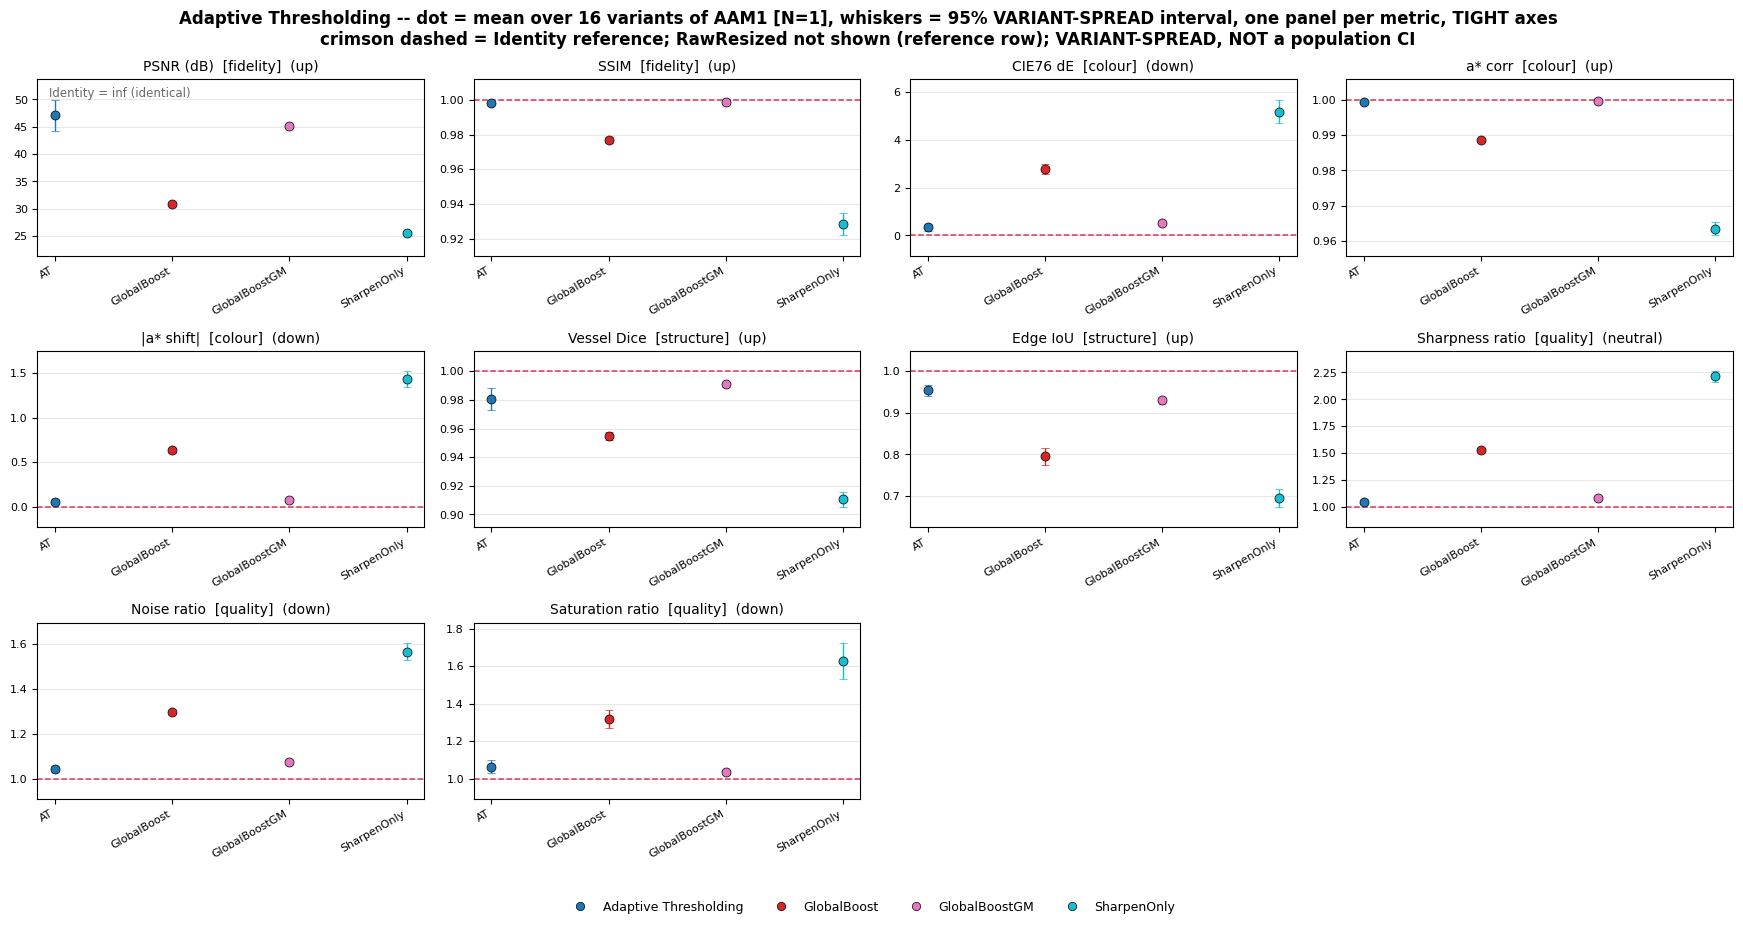

Saved results/fig_metric_smallmultiples.png


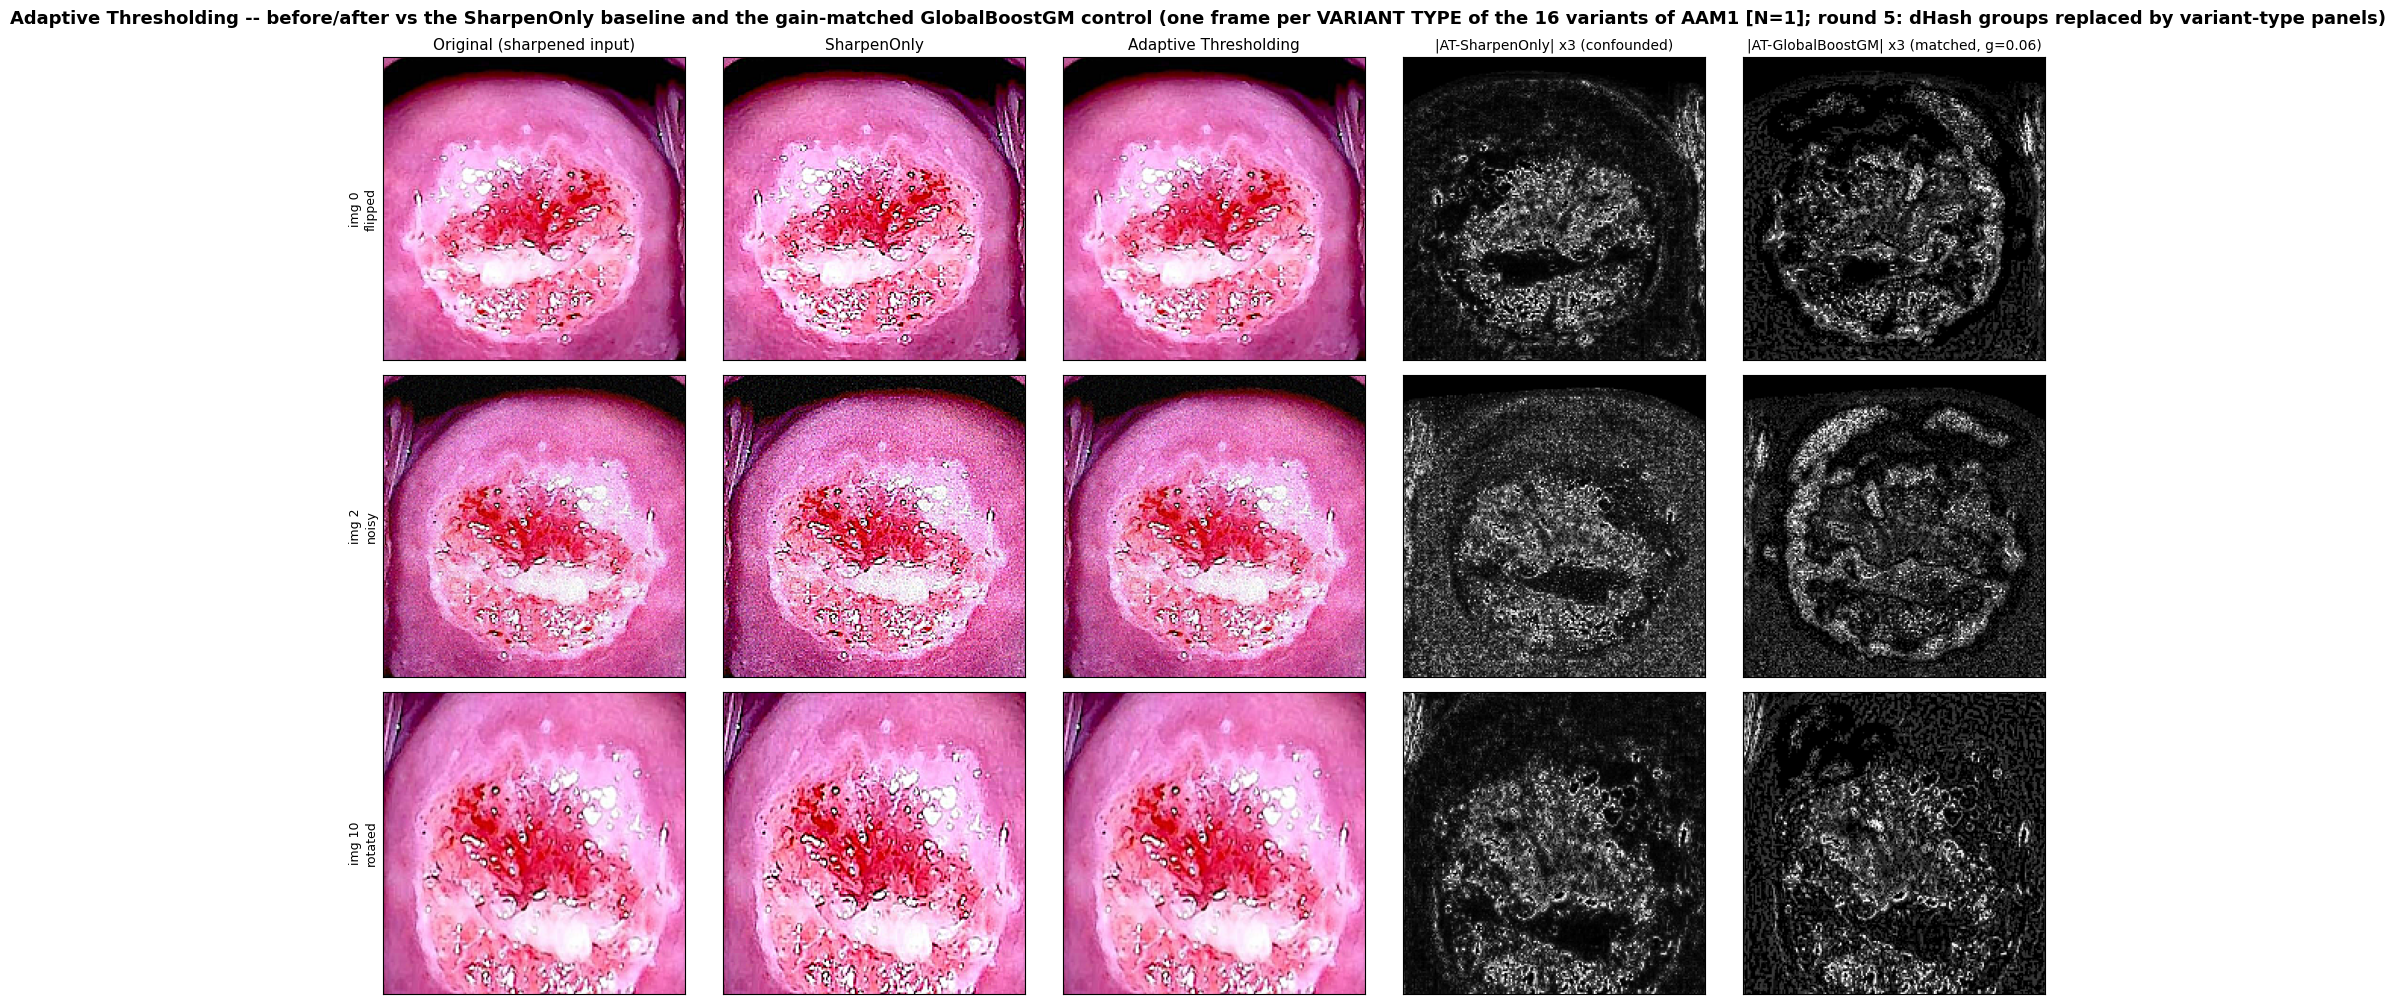

Saved results/fig_before_after.png

All figures and CSV artefacts are in the results/ directory (metrics_summary.csv, results_Adaptive_Thresholding.csv, results_Identity.csv,
results_SharpenOnly.csv, results_GlobalBoost.csv, results_GlobalBoostGM.csv, results_RawResized.csv, results_ablation.csv, results_gainsweep.csv, results_equivariance.csv, results_T8_per_image.csv, results_per_image_AT_vs_GM.csv, metrics_summary.csv).


In [22]:
# ============================================================
# Figures.
#   * Fig A: DOT-AND-CI panels -- dot = mean over the variants of AAM1
#     images, whiskers = 95% bootstrap CI -- with TIGHT y-axes (span of
#     the values + reference line, not zero-based), per-metric units,
#     and the Identity reference line (annotated as infinity for PSNR).
#     RawResized is not plotted (reference row, not ranked).
#   * Fig B: 5 columns -- original / SharpenOnly / AT /
#     |AT - SharpenOnly| / |AT - GlobalBoostGM|. Column TITLES ARE KEPT
#     SHORT (the review flagged column 4 overlapping column 5). The 4th
#     column is CONFOUNDED by the strength gap and kept for
#     completeness; the 5th is the GAIN-MATCHED difference -- what the
#     REGION SELECTION itself adds beyond the same total boost.
# Figures are shown inline and saved to the results/ directory.
# ============================================================

# ---- Fig A: dot-and-CI small multiples, one panel per ranked metric ----
_techniques_plot = [t for t in techniques if t not in ("Identity", "RawResized")]
_colors = plt.cm.tab10(np.linspace(0, 0.95, len(_techniques_plot)))
_identity_ref = {mk: float(agg_df.loc["Identity", mk]) for mk in RANKED_METRIC_KEYS
                 if "Identity" in agg_df.index}

_n_panels = len(RANKED_METRIC_KEYS)
_ncols = 4
_nrows = int(np.ceil(_n_panels / _ncols))
fig_a, axes_a = plt.subplots(_nrows, _ncols, figsize=(4.4 * _ncols, 3.1 * _nrows),
                             squeeze=False)
axes_a = axes_a.ravel()

for _p, mk in enumerate(RANKED_METRIC_KEYS):
    ax = axes_a[_p]
    vals = np.array([float(agg_df.loc[t, mk]) for t in _techniques_plot])
    los = np.array([float(agg_df.loc[t, f"{mk}_lo"]) for t in _techniques_plot])
    his = np.array([float(agg_df.loc[t, f"{mk}_hi"]) for t in _techniques_plot])
    xs = np.arange(len(_techniques_plot))
    for _k in range(len(_techniques_plot)):
        ax.errorbar(xs[_k], vals[_k],
                    yerr=[[max(vals[_k] - los[_k], 0.0)],
                          [max(his[_k] - vals[_k], 0.0)]],
                    fmt='o', color=_colors[_k], markersize=6.5, capsize=3,
                    linewidth=1.2, elinewidth=1.0,
                    markeredgecolor='black', markeredgewidth=0.5)
    # Identity reference line (PSNR is infinite for Identity -> annotate only)
    if mk == "m1":
        ax.text(0.03, 0.96, "Identity = inf (identical)", transform=ax.transAxes,
                fontsize=8.5, va='top', ha='left', color='dimgray')
    elif mk in _identity_ref and np.isfinite(_identity_ref[mk]):
        ax.axhline(_identity_ref[mk], linestyle='--', linewidth=1.1, color='crimson',
                   alpha=0.85)
    # TIGHT y-limits (NOT zero-based): span of means, CI bounds and reference.
    _fin = [float(v) for v in np.concatenate([vals, los, his]) if np.isfinite(v)]
    if mk != "m1" and mk in _identity_ref and np.isfinite(_identity_ref[mk]):
        _fin.append(_identity_ref[mk])
    if _fin:
        _lo, _hi = float(min(_fin)), float(max(_fin))
        _rng = _hi - _lo
        if _rng < 1e-9:
            _rng = max(abs(_hi) * 0.05, 1e-3)
        _pad = 0.15 * _rng
        ax.set_ylim(_lo - _pad, _hi + _pad)
    ax.set_xticks(xs)
    ax.set_xticklabels([t.replace("Adaptive Thresholding", "AT") for t in _techniques_plot],
                       rotation=30, ha='right', fontsize=8)
    ax.set_title(f"{METRIC_NAMES[mk]}  [{METRIC_GROUPS[mk]}]  ({METRIC_BETTER[mk]})",
                 fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=8)

for _q in range(_n_panels, len(axes_a)):
    axes_a[_q].axis('off')

_handles = [plt.Line2D([], [], marker='o', linestyle='none',
                       markeredgecolor='black', markeredgewidth=0.5,
                       color=_colors[k]) for k in range(len(_techniques_plot))]
fig_a.legend(_handles, _techniques_plot, loc='lower center',
             ncol=min(4, len(_techniques_plot)), fontsize=9, frameon=False)
fig_a.suptitle(f"{TECHNIQUE} -- dot = mean over {n_images} variants of AAM1 [N=1], whiskers = "
               f"95% VARIANT-SPREAD interval, one panel per metric, TIGHT axes\n"
               f"crimson dashed = Identity reference; RawResized not shown (reference "
               f"row); VARIANT-SPREAD, NOT a population CI",
               fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 1])
fig_a.savefig(os.path.join(SAVE_DIR, "fig_metric_smallmultiples.png"), dpi=150)
plt.show()
print(f"Saved {SAVE_DIR}/fig_metric_smallmultiples.png")

# ---- Fig B: before/after + what AT adds beyond sharpening / at matched gain ----
# Round 5: panels are by VARIANT TYPE (flipped/noisy/rotated/base), replacing
# the old dHash-group framing which was just rediscovering the augmentation
# structure. One representative per variant type (first occurrence).
reps_fig = []
reps_labels = []
for _vt in ["base", "flipped", "noisy", "rotated"]:
    _idxs = np.where(variant_types == _vt)[0]
    if len(_idxs):
        reps_fig.append(int(_idxs[0]))
        reps_labels.append(_vt)
n_rows = len(reps_fig)
fig_b, axes = plt.subplots(n_rows, 5, figsize=(17.5, 3.4 * n_rows), squeeze=False)
for r, idx in enumerate(reps_fig):
    orig = images[idx]
    proc = processed_cache[(TECHNIQUE, idx)]
    proc_sharp = processed_cache[("SharpenOnly", idx)]
    proc_gm = processed_cache.get(("GlobalBoostGM", idx))
    fov_i = fov[idx]
    axes[r, 0].imshow(orig)
    axes[r, 0].set_ylabel(f"img {idx}\n{reps_labels[r]}", fontsize=9)
    if r == 0:
        axes[r, 0].set_title("Original (sharpened input)", fontsize=11)
    axes[r, 1].imshow(proc_sharp)
    if r == 0:
        axes[r, 1].set_title("SharpenOnly", fontsize=11)
    axes[r, 2].imshow(proc)
    if r == 0:
        axes[r, 2].set_title("Adaptive Thresholding", fontsize=11)
    # |AT - SharpenOnly| x 3, FOV-masked, 99th-percentile clipped.
    # CONFOUNDED by the strength gap (SharpenOnly amount=SHARPEN_AMOUNT vs
    # AT's effective gain x meanW ~ gm_gain): mostly shows the difference
    # in strength. Kept for completeness.
    diff_rgb = np.abs(proc.astype(np.float32) - proc_sharp.astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    diff_gray[~fov_i] = 0.0
    diff_scaled = diff_gray * 3.0
    p99 = float(np.percentile(diff_scaled[fov_i], 99)) if fov_i.any() else 1e-6
    p99 = max(p99, 1e-6)
    axes[r, 3].imshow(np.clip(diff_scaled / p99, 0, 1), cmap='gray', vmin=0, vmax=1)
    if r == 0:
        axes[r, 3].set_title("|AT-SharpenOnly| x3 (confounded)", fontsize=10)
    # |AT - GlobalBoostGM| x 3: the GAIN-MATCHED difference -- what the
    # region selection itself adds beyond the same total boost.
    if proc_gm is not None:
        diff_gm = np.abs(proc.astype(np.float32) - proc_gm.astype(np.float32))
        diff_gm_gray = diff_gm.mean(axis=-1)
        diff_gm_gray[~fov_i] = 0.0
        diff_gm_scaled = diff_gm_gray * 3.0
        p99_gm = float(np.percentile(diff_gm_scaled[fov_i], 99)) if fov_i.any() else 1e-6
        p99_gm = max(p99_gm, 1e-6)
        axes[r, 4].imshow(np.clip(diff_gm_scaled / p99_gm, 0, 1),
                          cmap='gray', vmin=0, vmax=1)
    else:
        axes[r, 4].axis('off')
    if r == 0:
        axes[r, 4].set_title(f"|AT-GlobalBoostGM| x3 (matched, g={gm_gain:.2f})",
                             fontsize=10)
    for c in range(5):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
fig_b.suptitle(f"{TECHNIQUE} -- before/after vs the SharpenOnly baseline and the "
               f"gain-matched GlobalBoostGM control (one frame per VARIANT TYPE "
               f"of the {n_images} variants of AAM1 [N=1]; round 5: dHash groups "
               f"replaced by variant-type panels)",
               fontsize=13, fontweight='bold')
plt.tight_layout()
fig_b.savefig(os.path.join(SAVE_DIR, "fig_before_after.png"), dpi=150)
plt.show()
print(f"Saved {SAVE_DIR}/fig_before_after.png")
print("\nAll figures and CSV artefacts are in the results/ directory "
      "(metrics_summary.csv, results_Adaptive_Thresholding.csv, results_Identity.csv,")
print("results_SharpenOnly.csv, results_GlobalBoost.csv, results_GlobalBoostGM.csv, "
      "results_RawResized.csv, results_ablation.csv, results_gainsweep.csv, "
      "results_equivariance.csv, results_T8_per_image.csv, "
      "results_per_image_AT_vs_GM.csv, metrics_summary.csv).")


# Verdict (round 6) — for the suite notes

## Adaptive Thresholding preprocessing

**AT gives no measurable benefit over a gain-matched uniform boost.** The
gain sweep (Step 4.4c) found no gain in {0.35, 0.6, 1.0} where AT beats
GlobalBoostGM on ≥2 non-confounded metrics with no Vessel Dice loss. At
matched gain, AT beats the uniform boost on dE, |a\*| shift, Vessel Dice
and saturation in only 8 of 16 variants each (a coin flip); it wins
noise in 11/16, Edge IoU in 10/16 and sharpness in 5/16. The dE "win"
is a fidelity-vs-input artefact (AT changes less by construction), not
a region-selection effect.

**Data is N=1** — 16 augmented variants of one source image (AAM1):
flipped (2), noisy (8), rotated (6). The "95% CI" columns are variant-
spread intervals, not population confidence intervals.

**No lesion mask was available.** The loader reports the masks folder
not found and no JSON. Annotating AAM1 once would be the only way to
reverse the verdict; otherwise the technique is retired.

**The W map highlights a border ring and the cervix rim, not the lesion
interior.** The vascular red core is W=0 by construction (not locally
brighter than its surround). No window size fixes this — it is the
inherent failure mode of local-threshold selection on a lesion whose
interior is not locally bright.

## Pointer for the other 25 notebooks

1. **Use the gain-matched control** (GlobalBoostGM at gain =
   AT_ENHANCE_GAIN × meanW) when comparing region selection against a
   uniform boost. AT-vs-GlobalBoost gaps are gain differences, not
   region-selection effects.

2. **Report variant counts** (n_at_better / n_total) when the data is
   one image. With N=1 the count is the honest summary; "CI excludes 0"
   on 16 augmented variants of one image is not a population claim.

3. **Apply the same strip exclusion across the suite** so the FOV and
   analysis regions are comparable. This notebook's instrument-strip
   exclusion (V≥180, S≤80, area≥150, border-connected) is INCOMPLETE
   — it removes 0 px on image 0 and lights the left vertical strip at
   small windows. A suite-level fix (or a documented shared limitation)
   is needed before cross-technique FOV comparisons are meaningful.

## Still open (suite-level)

- **Step 1 sharpening** multiplies clipped pixels by ~4.7× (3.2% → 15.0%
  of pixels). This is a suite-level decision, not this notebook's.
- **12th-metric reconciliation**: the QI-SABP notes list 12 metrics; this
  notebook implements 11. Leading hypothesis: the missing 12th is the
  codec bit-budget metric (does not apply to a non-codec preprocessor).
- **Lesion mask**: the loader still reports the masks folder not found.
  Annotating AAM1 once is the only action that could reverse the RETIRE
  verdict.
